In [1]:
import configparser
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from venn import venn

In [2]:
os.chdir('../')

In [3]:
dataset = 'all_noHypoHyper'

In [4]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('data.ini')
data = data['DEFAULT']

In [5]:
qfreq = 0.001

# Choose Thresholds

## mutsig

In [6]:
mutsig = pd.read_csv(data[f'mutsig___{dataset}___out_dir'] + '/sig_genes.txt', sep='\t', engine='python', comment='#')
mutsig_RAS = pd.read_csv(data[f'mutsig___{dataset}_RAS___out_dir'] + '/sig_genes.txt', sep='\t', engine='python', comment='#')
mutsig_nonRAS = pd.read_csv(data[f'mutsig___{dataset}_nonRAS___out_dir'] + '/sig_genes.txt', sep='\t', engine='python', comment='#')

In [7]:
synonims = pd.read_csv('data/mutSig2CV/synonyms_final.csv', sep='\t')

In [8]:
# rename mutsig genes using synonyms
mutsig['gene'] = mutsig['gene'].apply(lambda x: synonims[synonims['mutsig_name'] == x]['choosen'].values[0] if x in synonims[synonims['choosen'].notna()]['mutsig_name'].values else x)
mutsig_RAS['gene'] = mutsig_RAS['gene'].apply(lambda x: synonims[synonims['mutsig_name'] == x]['choosen'].values[0] if x in synonims[synonims['choosen'].notna()]['mutsig_name'].values else x)
mutsig_nonRAS['gene'] = mutsig_nonRAS['gene'].apply(lambda x: synonims[synonims['mutsig_name'] == x]['choosen'].values[0] if x in synonims[synonims['choosen'].notna()]['mutsig_name'].values else x)

### p-value

In [9]:
mutsig_numGenes_pvLower = pd.DataFrame(
    [(i, len(mutsig.loc[mutsig['p'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)
mutsig_numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(mutsig_RAS.loc[mutsig_RAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)

mutsig_numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(mutsig_nonRAS.loc[mutsig_nonRAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)

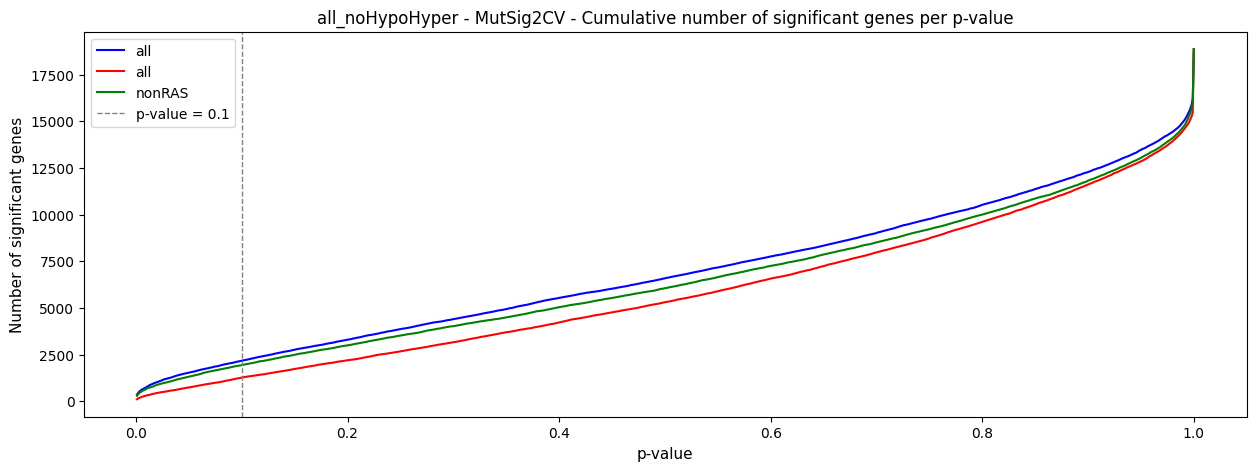

In [10]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MutSig2CV - Cumulative number of significant genes per p-value')
plt.plot(mutsig_numGenes_pvLower.set_index('p-value'), label='all', color='blue')
plt.plot(mutsig_numGenes_pvLower_RAS.set_index('p-value'), label='all', color='red')
plt.plot(mutsig_numGenes_pvLower_nonRAS.set_index('p-value'), label='nonRAS', color='green')
plt.axvline(x=0.1, color='grey', linestyle='--', linewidth=1, label='p-value = 0.1')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'mutsig_cumulativeNumSignificantGenes_perPV.png')
plt.show()

In [11]:
mutsig_p_significant = 0.1

In [12]:
mutsig_p_sGenes_all = set(mutsig.loc[mutsig['p'] < mutsig_p_significant, 'gene'])
mutsig_p_sGenes_RAS = set(mutsig_RAS.loc[mutsig_RAS['p'] < mutsig_p_significant, 'gene'])
mutsig_p_sGenes_nonRAS = set(mutsig_nonRAS.loc[mutsig_nonRAS['p'] < mutsig_p_significant, 'gene'])
mutsig_p_sGenes_onlyRAS = set.difference(set(mutsig_p_sGenes_RAS), set(mutsig_p_sGenes_nonRAS))
len(mutsig_p_sGenes_all), len(mutsig_p_sGenes_RAS), len(mutsig_p_sGenes_nonRAS), len(mutsig_p_sGenes_onlyRAS)

(2178, 1276, 1940, 908)

### q-value

In [13]:
mutsig_numGenes_qvLower = pd.DataFrame(
    [(i, len(mutsig.loc[mutsig['q'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)
mutsig_numGenes_qvLower_RAS = pd.DataFrame(
    [(i, len(mutsig_RAS.loc[mutsig_RAS['q'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)
mutsig_numGenes_qvLower_nonRAS = pd.DataFrame(
    [(i, len(mutsig_nonRAS.loc[mutsig_nonRAS['q'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)

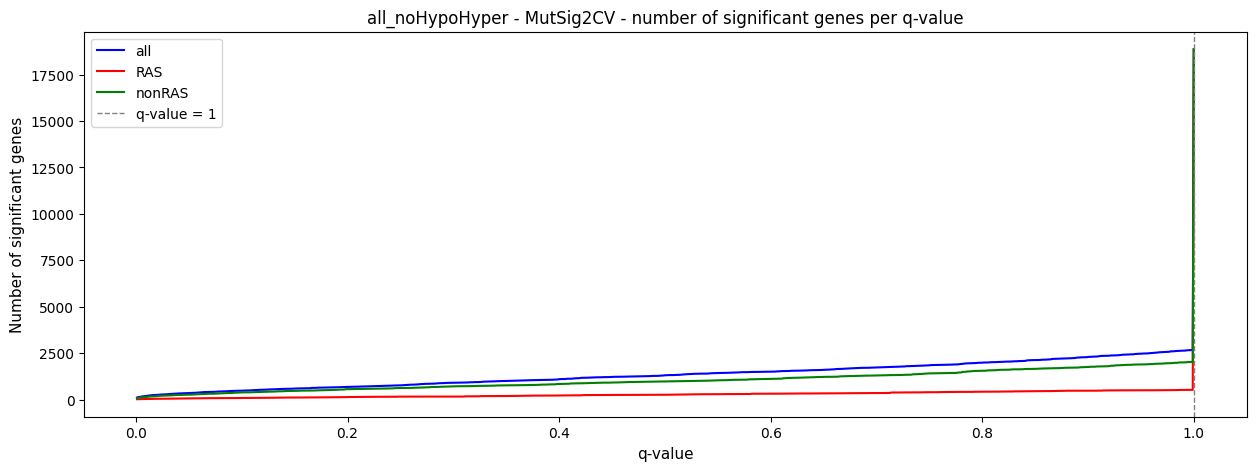

In [14]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MutSig2CV - number of significant genes per q-value')
plt.plot(mutsig_numGenes_qvLower.set_index('q-value'), label='all', color='blue')
plt.plot(mutsig_numGenes_qvLower_RAS.set_index('q-value'), label='RAS', color='red')
plt.plot(mutsig_numGenes_qvLower_nonRAS.set_index('q-value'), label='nonRAS', color='green')
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1, label='q-value = 1')
plt.xlabel('q-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'mutsig_cumulativeNumSignificantGenes_perQV.png')
plt.show()

In [15]:
mutsig_q_significant = 1

In [16]:
mutsig_q_sGenes_all = set(mutsig.loc[mutsig['q'] < mutsig_q_significant, 'gene'])
mutsig_q_sGenes_RAS = set(mutsig_RAS.loc[mutsig_RAS['q'] < mutsig_q_significant, 'gene'])
mutsig_q_sGenes_nonRAS = set(mutsig_nonRAS.loc[mutsig_nonRAS['q'] < mutsig_q_significant, 'gene'])
mutsig_q_sGenes_onlyRAS = set.difference(set(mutsig_q_sGenes_RAS), set(mutsig_q_sGenes_nonRAS))
mutsig_q_sGenes_onlyNonRAS = set.difference(set(mutsig_q_sGenes_nonRAS), set(mutsig_q_sGenes_RAS))
mutsig_q_sGenes_onlyRAS_onlyNonRAS = set.union(mutsig_q_sGenes_onlyRAS, mutsig_q_sGenes_onlyNonRAS)
len(mutsig_q_sGenes_all), len(mutsig_q_sGenes_RAS), len(mutsig_q_sGenes_nonRAS), len(mutsig_q_sGenes_onlyRAS), len(mutsig_q_sGenes_onlyNonRAS), len(mutsig_q_sGenes_onlyRAS_onlyNonRAS)

(2675, 526, 2028, 307, 1809, 2116)

## driverml

In [17]:
driverml = pd.read_csv(data[f'driverml___{dataset}___out'], sep='\t', engine='python', comment='#')
driverml_RAS = pd.read_csv(data[f'driverml___{dataset}_RAS___out'], sep='\t', engine='python', comment='#')
driverml_nonRAS = pd.read_csv(data[f'driverml___{dataset}_nonRAS___out'], sep='\t', engine='python', comment='#')

### p-value

In [18]:
driverml_numGenes_pvLower = pd.DataFrame(
    [(i, len(driverml.loc[driverml['p'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)
driverml_numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(driverml_RAS.loc[driverml_RAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)
driverml_numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(driverml_nonRAS.loc[driverml_nonRAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)

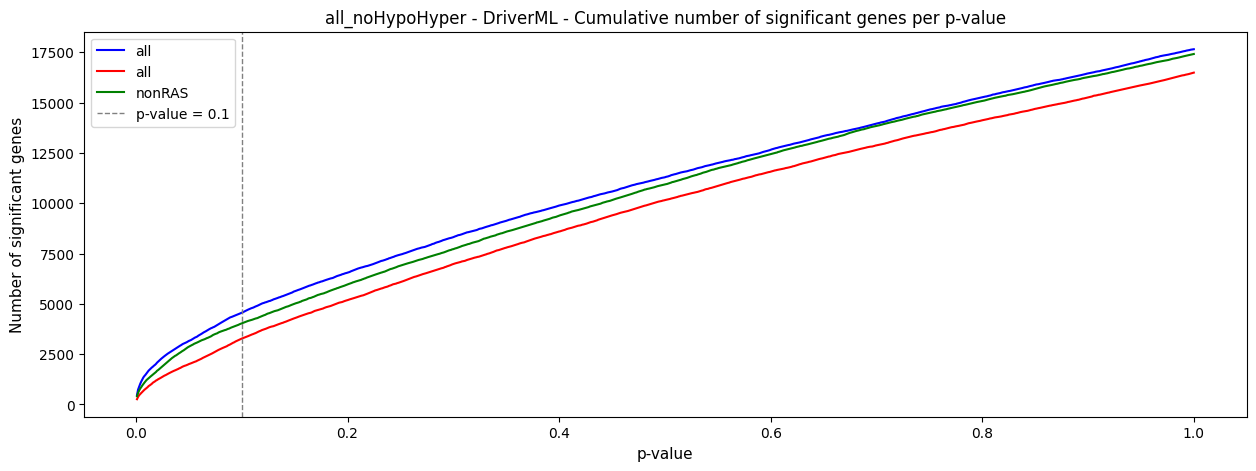

In [19]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - DriverML - Cumulative number of significant genes per p-value')
plt.plot(driverml_numGenes_pvLower.set_index('p-value'), label='all', color='blue')
plt.plot(driverml_numGenes_pvLower_RAS.set_index('p-value'), label='all', color='red')
plt.plot(driverml_numGenes_pvLower_nonRAS.set_index('p-value'), label='nonRAS', color='green')
plt.axvline(x=0.1, color='grey', linestyle='--', linewidth=1, label='p-value = 0.1')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'driverml_cumulativeNumSignificantGenes_perPV.png')
plt.show()

In [20]:
driverml_p_significant = 0.1

In [21]:
driverml_p_sGenes_all = set(driverml.loc[driverml['p'] < driverml_p_significant, 'gene'])
driverml_p_sGenes_RAS = set(driverml_RAS.loc[driverml_RAS['p'] < driverml_p_significant, 'gene'])
driverml_p_sGenes_nonRAS = set(driverml_nonRAS.loc[driverml_nonRAS['p'] < driverml_p_significant, 'gene'])
driverml_p_sGenes_onlyRAS = set.difference(set(driverml_p_sGenes_RAS), set(driverml_p_sGenes_nonRAS))
len(driverml_p_sGenes_all), len(driverml_p_sGenes_RAS), len(driverml_p_sGenes_nonRAS), len(driverml_p_sGenes_onlyRAS)

(4559, 3272, 4031, 1956)

### q-value

In [22]:
driverml_numGenes_qvLower = pd.DataFrame(
    [(i, len(driverml.loc[driverml['p_adj'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)
driverml_numGenes_qvLower_RAS = pd.DataFrame(
    [(i, len(driverml_RAS.loc[driverml_RAS['p_adj'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)
driverml_numGenes_qvLower_nonRAS = pd.DataFrame(
    [(i, len(driverml_nonRAS.loc[driverml_nonRAS['p_adj'] <= i, 'gene'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)

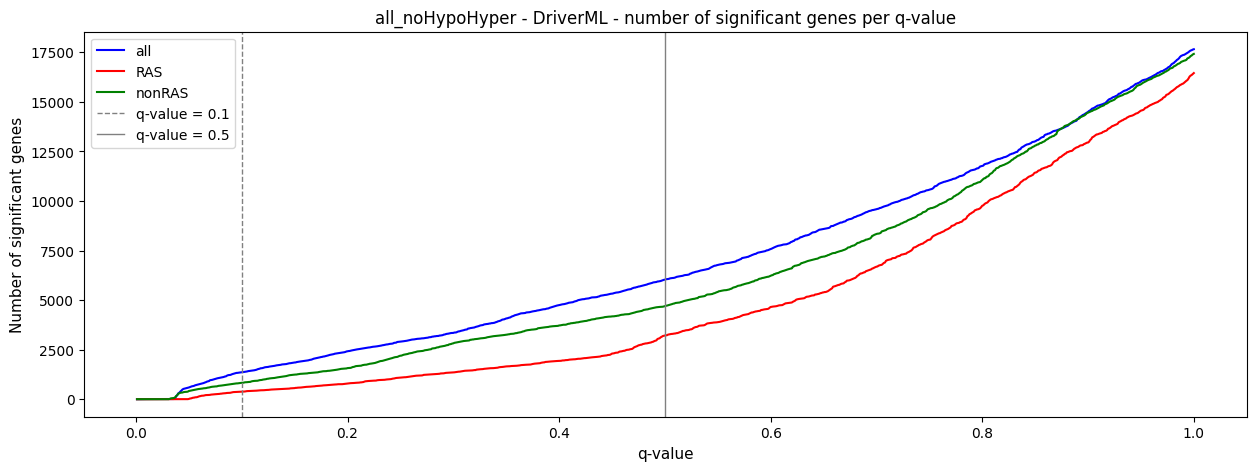

In [23]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - DriverML - number of significant genes per q-value')
plt.plot(driverml_numGenes_qvLower.set_index('q-value'), label='all', color='blue')
plt.plot(driverml_numGenes_qvLower_RAS.set_index('q-value'), label='RAS', color='red')
plt.plot(driverml_numGenes_qvLower_nonRAS.set_index('q-value'), label='nonRAS', color='green')
plt.axvline(x=0.1, color='grey', linestyle='--', linewidth=1, label='q-value = 0.1')
plt.axvline(x=0.5, color='grey', linestyle='-', linewidth=1, label='q-value = 0.5')
plt.xlabel('q-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'driverml_cumulativeNumSignificantGenes_perQV.png')
plt.show()

In [24]:
# dividere curva intervalli
# retta in intervallo
# individuo massimo scostamento
# divido intervallo in sotto intervalli etc

In [25]:
driverml_q_significant = 0.5

In [26]:
driverml_q_sGenes_all = set(driverml.loc[driverml['p_adj'] < driverml_q_significant, 'gene'])
driverml_q_sGenes_RAS = set(driverml_RAS.loc[driverml_RAS['p_adj'] < driverml_q_significant, 'gene'])
driverml_q_sGenes_nonRAS = set(driverml_nonRAS.loc[driverml_nonRAS['p_adj'] < driverml_q_significant, 'gene'])
driverml_q_sGenes_onlyRAS = set.difference(set(driverml_q_sGenes_RAS), set(driverml_q_sGenes_nonRAS))
driverml_q_sGenes_onlyNonRAS = set.difference(set(driverml_q_sGenes_nonRAS), set(driverml_q_sGenes_RAS))
driverml_q_sGenes_onlyRAS_onlyNonRAS = set.union(driverml_q_sGenes_onlyRAS, driverml_q_sGenes_onlyNonRAS)
len(driverml_q_sGenes_all), len(driverml_q_sGenes_RAS), len(driverml_q_sGenes_nonRAS), len(driverml_q_sGenes_onlyRAS), len(driverml_q_sGenes_onlyNonRAS), len(driverml_q_sGenes_onlyRAS_onlyNonRAS)

(6032, 3214, 4695, 1798, 3279, 5077)

## mutpanning

In [27]:
mutpanning = pd.read_csv(data[f'mutpanning___{dataset}___out_dir'] + '/SignificanceFiltered/Significancecolorectal.txt', sep='\t', engine='python', comment='#')
mutpanning_RAS = pd.read_csv(data[f'mutpanning___{dataset}_RAS___out_dir'] + '/SignificanceFiltered/Significancecolorectal.txt', sep='\t', engine='python', comment='#')
mutpanning_nonRAS = pd.read_csv(data[f'mutpanning___{dataset}_nonRAS___out_dir'] + '/SignificanceFiltered/Significancecolorectal.txt', sep='\t', engine='python', comment='#')

### p-value

In [28]:
mutpanning_numGenes_pvLower = pd.DataFrame(
    [(i, len(mutpanning.loc[mutpanning['Significance'] <= i, 'Name'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)
mutpanning_numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(mutpanning_RAS.loc[mutpanning_RAS['Significance'] <= i, 'Name'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)
mutpanning_numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(mutpanning_nonRAS.loc[mutpanning_nonRAS['Significance'] <= i, 'Name'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)

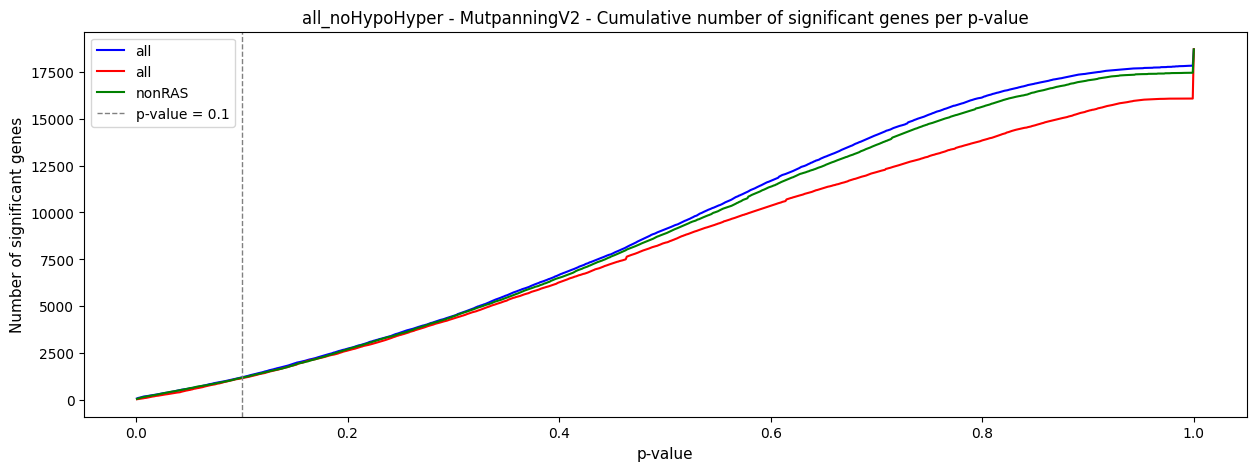

In [29]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MutpanningV2 - Cumulative number of significant genes per p-value')
plt.plot(mutpanning_numGenes_pvLower.set_index('p'), label='all', color='blue')
plt.plot(mutpanning_numGenes_pvLower_RAS.set_index('p'), label='all', color='red')
plt.plot(mutpanning_numGenes_pvLower_nonRAS.set_index('p'), label='nonRAS', color='green')
plt.axvline(x=0.1, color='grey', linestyle='--', linewidth=1, label='p-value = 0.1')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'mutpanning_cumulativeNumSignificantGenes_perPV.png')
plt.show()

In [30]:
mutpanning_p_significant = 0.1

In [31]:
mutpanning_p_sGenes_all = set(mutpanning.loc[mutpanning['Significance'] < mutpanning_p_significant, 'Name'])
mutpanning_p_sGenes_RAS = set(mutpanning_RAS.loc[mutpanning_RAS['Significance'] < mutpanning_p_significant, 'Name'])
mutpanning_p_sGenes_nonRAS = set(mutpanning_nonRAS.loc[mutpanning_nonRAS['Significance'] < mutpanning_p_significant, 'Name'])
mutpanning_p_sGenes_onlyRAS = set.difference(set(mutpanning_p_sGenes_RAS), set(mutpanning_p_sGenes_nonRAS))
len(mutpanning_p_sGenes_all), len(mutpanning_p_sGenes_RAS), len(mutpanning_p_sGenes_nonRAS), len(mutpanning_p_sGenes_onlyRAS)

(1220, 1174, 1199, 886)

### q-value

In [32]:
mutpanning_numGenes_qvLower = pd.DataFrame(
    [(i, len(mutpanning.loc[mutpanning['FDR'] <= i, 'Name'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q', 'numGenes']
)
mutpanning_numGenes_qvLower_RAS = pd.DataFrame(
    [(i, len(mutpanning_RAS.loc[mutpanning_RAS['FDR'] <= i, 'Name'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q', 'numGenes']
)
mutpanning_numGenes_qvLower_nonRAS = pd.DataFrame(
    [(i, len(mutpanning_nonRAS.loc[mutpanning_nonRAS['FDR'] <= i, 'Name'])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['q', 'numGenes']
)

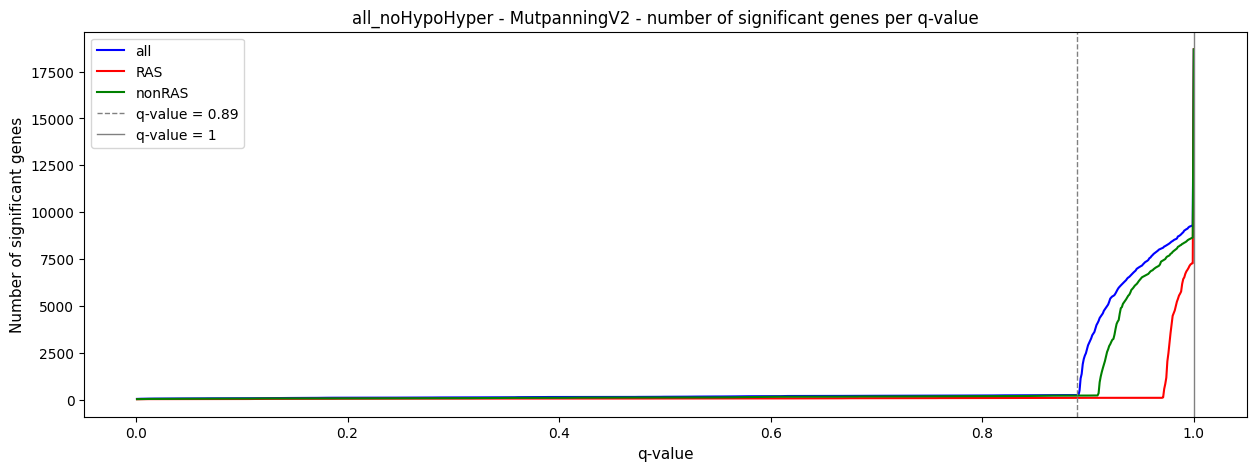

In [33]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MutpanningV2 - number of significant genes per q-value')
plt.plot(mutpanning_numGenes_qvLower.set_index('q'), label='all', color='blue')
plt.plot(mutpanning_numGenes_qvLower_RAS.set_index('q'), label='RAS', color='red')
plt.plot(mutpanning_numGenes_qvLower_nonRAS.set_index('q'), label='nonRAS', color='green')
plt.axvline(x=0.89, color='grey', linestyle='--', linewidth=1, label='q-value = 0.89')
plt.axvline(x=1, color='grey', linestyle='-', linewidth=1, label='q-value = 1')
plt.xlabel('q-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'mutpanning_cumulativeNumSignificantGenes_perQV.png')
plt.show()

In [34]:
mutpanning_q_significant = 1

In [35]:
mutpanning_q_sGenes_all = set(mutpanning.loc[mutpanning['FDR'] < mutpanning_q_significant, 'Name'])
mutpanning_q_sGenes_RAS = set(mutpanning_RAS.loc[mutpanning_RAS['FDR'] < mutpanning_q_significant, 'Name'])
mutpanning_q_sGenes_nonRAS = set(mutpanning_nonRAS.loc[mutpanning_nonRAS['FDR'] < mutpanning_q_significant, 'Name'])
mutpanning_q_sGenes_onlyRAS = set.difference(set(mutpanning_q_sGenes_RAS), set(mutpanning_q_sGenes_nonRAS))
mutpanning_q_sGenes_onlyNonRAS = set.difference(set(mutpanning_q_sGenes_nonRAS), set(mutpanning_q_sGenes_RAS))
mutpanning_q_sGenes_onlyRAS_onlyNonRAS = set.union(mutpanning_q_sGenes_onlyRAS, mutpanning_q_sGenes_onlyNonRAS)
len(mutpanning_q_sGenes_all), len(mutpanning_q_sGenes_RAS), len(mutpanning_q_sGenes_nonRAS), len(mutpanning_q_sGenes_onlyRAS), len(mutpanning_q_sGenes_onlyNonRAS), len(mutpanning_q_sGenes_onlyRAS_onlyNonRAS)

(9333, 7324, 8687, 3421, 4784, 8205)

## netsig

In [36]:
netsig = pd.read_csv(data[f'netsig___{dataset}___out_dir'] + '/all_noHypoHyper_j1_J1_i1000_f0_g01_P3_r0_m1.txt', sep='\t', engine='python', comment='#', header=None)
netsig.columns = ['gene', 'score', 'p']
netsig_RAS = pd.read_csv(data[f'netsig___{dataset}_RAS___out_dir'] + '/all_noHypoHyper_RAS_j1_J1_i1000_f0_g01_P3_r0_m1.txt', sep='\t', engine='python', comment='#', header=None)
netsig_RAS.columns = ['gene', 'score', 'p']
netsig_nonRAS = pd.read_csv(data[f'netsig___{dataset}_nonRAS___out_dir'] + '/all_noHypoHyper_nonRAS_j1_J1_i1000_f0_g01_P3_r0_m1.txt', sep='\t', engine='python', comment='#', header=None)
netsig_nonRAS.columns = ['gene', 'score', 'p']

### p-value

In [37]:
netsig_numGenes_pvLower = pd.DataFrame(
    [(i, len(netsig.loc[netsig['p'] <= i])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)
netsig_numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(netsig_RAS.loc[netsig_RAS['p'] <= i])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)
netsig_numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(netsig_nonRAS.loc[netsig_nonRAS['p'] <= i])) for i in np.clip(np.arange(qfreq, 1+qfreq, qfreq), a_min=0, a_max=1)],
    columns=['p', 'numGenes']
)

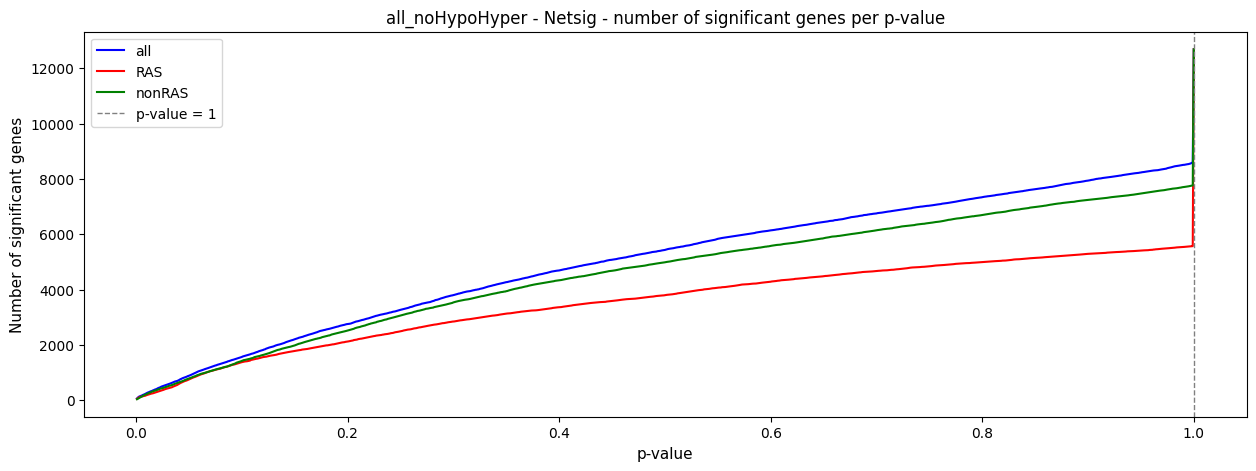

In [38]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Netsig - number of significant genes per p-value')
plt.plot(netsig_numGenes_pvLower.set_index('p'), label='all', color='blue')
plt.plot(netsig_numGenes_pvLower_RAS.set_index('p'), label='RAS', color='red')
plt.plot(netsig_numGenes_pvLower_nonRAS.set_index('p'), label='nonRAS', color='green')
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1, label='p-value = 1')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'netsig_cumulativeNumSignificantGenes_perPV.png')
plt.show()

In [39]:
netsig_p_significant = 1

In [40]:
netsig_p_sGenes_all = set(netsig.loc[netsig['p'] < netsig_p_significant, 'gene'])
netsig_p_sGenes_RAS = set(netsig_RAS.loc[netsig_RAS['p'] < netsig_p_significant, 'gene'])
netsig_p_sGenes_nonRAS = set(netsig_nonRAS.loc[netsig_nonRAS['p'] < netsig_p_significant, 'gene'])
netsig_p_sGenes_onlyRAS = set.difference(set(netsig_p_sGenes_RAS), set(netsig_p_sGenes_nonRAS))
netsig_p_sGenes_onlyNonRAS = set.difference(set(netsig_p_sGenes_nonRAS), set(netsig_p_sGenes_RAS))
netsig_p_sGenes_onlyRAS_onlyNonRAS = set.union(netsig_p_sGenes_onlyRAS, netsig_p_sGenes_onlyNonRAS)
len(netsig_p_sGenes_all), len(netsig_p_sGenes_RAS), len(netsig_p_sGenes_nonRAS), len(netsig_p_sGenes_onlyRAS), len(netsig_p_sGenes_onlyNonRAS), len(netsig_p_sGenes_onlyRAS_onlyNonRAS)

(8603, 5577, 7776, 476, 2675, 3151)

## maxmif

In [41]:
maxmifHN = pd.read_csv(data[f'maxmif___{dataset}___out_dir'] + '/MaxMIF_all_noHypoHyper_HumanNet.txt', sep='\t', engine='python', comment='#')
maxmifS = pd.read_csv(data[f'maxmif___{dataset}___out_dir'] + '/MaxMIF_all_noHypoHyper_STRINGv10.txt', sep='\t', engine='python', comment='#')
maxmifHN_RAS = pd.read_csv(data[f'maxmif___{dataset}_RAS___out_dir'] + '/MaxMIF_all_noHypoHyper_RAS_HumanNet.txt', sep='\t', engine='python', comment='#')
maxmifS_RAS = pd.read_csv(data[f'maxmif___{dataset}_RAS___out_dir'] + '/MaxMIF_all_noHypoHyper_RAS_STRINGv10.txt', sep='\t', engine='python', comment='#')
maxmifHN_nonRAS = pd.read_csv(data[f'maxmif___{dataset}_nonRAS___out_dir'] + '/MaxMIF_all_noHypoHyper_nonRAS_HumanNet.txt', sep='\t', engine='python', comment='#')
maxmifS_nonRAS = pd.read_csv(data[f'maxmif___{dataset}_nonRAS___out_dir'] + '/MaxMIF_all_noHypoHyper_nonRAS_STRINGv10.txt', sep='\t', engine='python', comment='#')

### HumanNet

In [42]:
maxmifHN_numGenes_sHigher = pd.DataFrame(
    [(i, len(maxmifHN.loc[maxmifHN['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, maxmifHN['MaxMIF-Score'].max() + qfreq, qfreq)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifHN_numGenes_sHigher_RAS = pd.DataFrame(
    [(i, len(maxmifHN_RAS.loc[maxmifHN_RAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, maxmifHN_RAS['MaxMIF-Score'].max() + qfreq, qfreq)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifHN_numGenes_sHigher_nonRAS = pd.DataFrame(
    [(i, len(maxmifHN_nonRAS.loc[maxmifHN_nonRAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, maxmifHN_nonRAS['MaxMIF-Score'].max() + qfreq, qfreq)],
    columns=['MaxMIF-Score', 'numGenes']
)

maxmifHN_numGenes_sHigher_zoom = pd.DataFrame(
    [(i, len(maxmifHN.loc[maxmifHN['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, 0.015 + 0.00001, 0.00001)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifHN_numGenes_sHigher_RAS_zoom = pd.DataFrame(
    [(i, len(maxmifHN_RAS.loc[maxmifHN_RAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, 0.015 + 0.00001, 0.00001)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifHN_numGenes_sHigher_nonRAS_zoom = pd.DataFrame(
    [(i, len(maxmifHN_nonRAS.loc[maxmifHN_nonRAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, 0.015 + 0.00001, 0.00001)],
    columns=['MaxMIF-Score', 'numGenes']
)

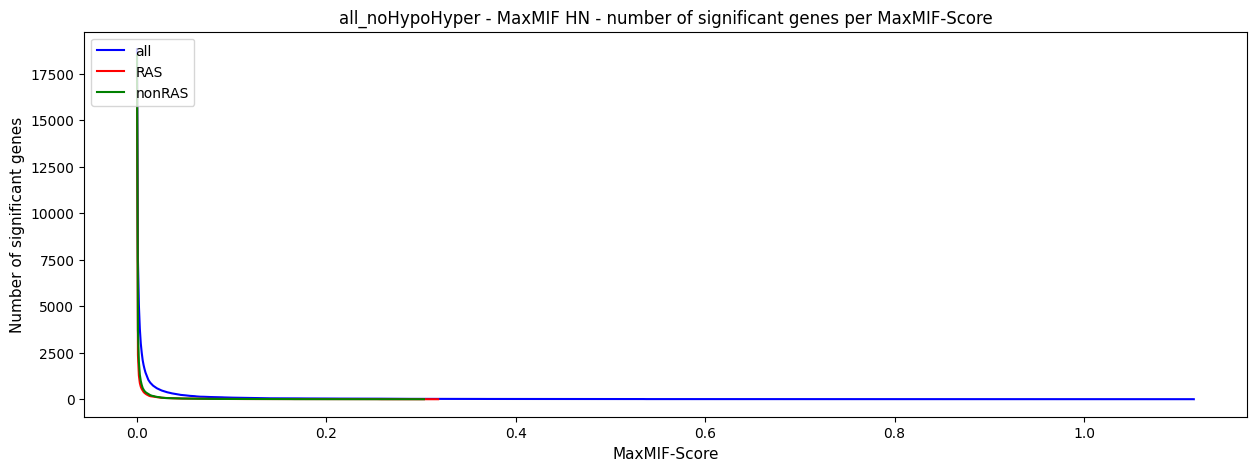

In [43]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MaxMIF HN - number of significant genes per MaxMIF-Score')
plt.plot(maxmifHN_numGenes_sHigher.set_index('MaxMIF-Score'), label='all', color='blue')
plt.plot(maxmifHN_numGenes_sHigher_RAS.set_index('MaxMIF-Score'), label='RAS', color='red')
plt.plot(maxmifHN_numGenes_sHigher_nonRAS.set_index('MaxMIF-Score'), label='nonRAS', color='green')
plt.xlabel('MaxMIF-Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'maxmifHN_cumulativeNumSignificantGenes_perMaxMIFScore_HumanNet.png')
plt.show()

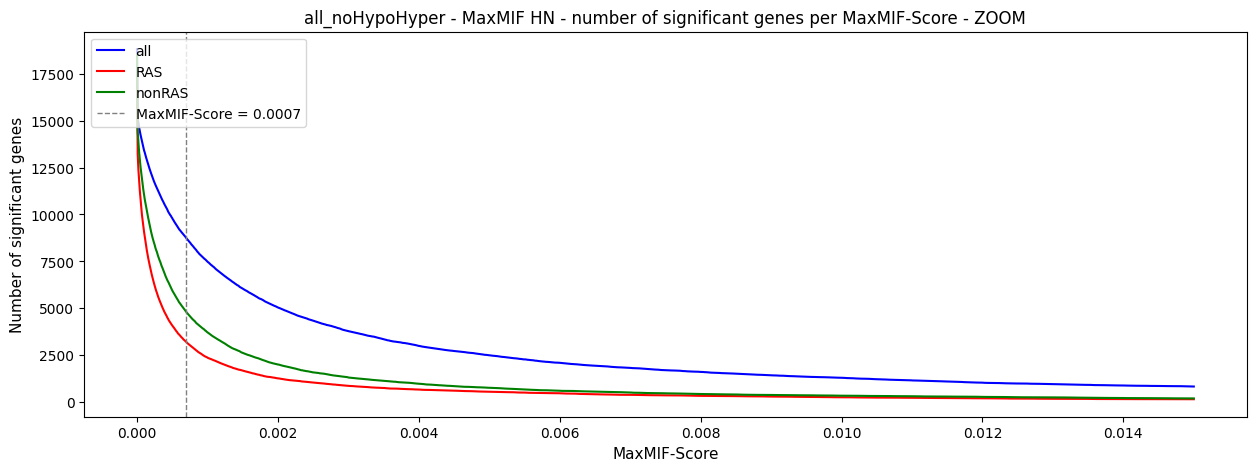

In [44]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MaxMIF HN - number of significant genes per MaxMIF-Score - ZOOM')
plt.plot(maxmifHN_numGenes_sHigher_zoom.set_index('MaxMIF-Score'), label='all', color='blue')
plt.plot(maxmifHN_numGenes_sHigher_RAS_zoom.set_index('MaxMIF-Score'), label='RAS', color='red')
plt.plot(maxmifHN_numGenes_sHigher_nonRAS_zoom.set_index('MaxMIF-Score'), label='nonRAS', color='green')
# plt.axvline(x=0.0001, color='grey', linestyle='--', linewidth=1, label='MaxMIF-Score = 0.0001')
plt.axvline(x=0.0007, color='grey', linestyle='--', linewidth=1, label='MaxMIF-Score = 0.0007')
# plt.axvline(x=0.005, color='grey', linestyle='-', linewidth=1, label='MaxMIF-Score = 0.005')
plt.xlabel('MaxMIF-Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'maxmifHN_cumulativeNumSignificantGenes_perMaxMIFScore_HumanNet_onlyAll_ZOOM.png')
plt.show()

In [45]:
maxmifHN_s_significant = 0.0007

In [46]:
maxmifHN_sGenes_all = set(maxmifHN.loc[maxmifHN['MaxMIF-Score'] > maxmifHN_s_significant, 'GeneSymbol'])
maxmifHN_sGenes_RAS = set(maxmifHN_RAS.loc[maxmifHN_RAS['MaxMIF-Score'] > maxmifHN_s_significant, 'GeneSymbol'])
maxmifHN_sGenes_nonRAS = set(maxmifHN_nonRAS.loc[maxmifHN_nonRAS['MaxMIF-Score'] > maxmifHN_s_significant, 'GeneSymbol'])
maxmifHN_sGenes_onlyRAS = set.difference(set(maxmifHN_sGenes_RAS), set(maxmifHN_sGenes_nonRAS))
maxmifHN_sGenes_onlyNonRAS = set.difference(set(maxmifHN_sGenes_nonRAS), set(maxmifHN_sGenes_RAS))
maxmifHN_sGenes_onlyRAS_onlyNonRAS = set.union(maxmifHN_sGenes_onlyRAS, maxmifHN_sGenes_onlyNonRAS)
len(maxmifHN_sGenes_all), len(maxmifHN_sGenes_RAS), len(maxmifHN_sGenes_nonRAS), len(maxmifHN_sGenes_onlyRAS), len(maxmifHN_sGenes_onlyNonRAS), len(maxmifHN_sGenes_onlyRAS_onlyNonRAS)

(8740, 3204, 4803, 443, 2042, 2485)

### STRINGv10

In [47]:
maxmifS_numGenes_sHigher = pd.DataFrame(
    [(i, len(maxmifS.loc[maxmifS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, maxmifS['MaxMIF-Score'].max() + qfreq, qfreq)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifS_numGenes_sHigher_RAS = pd.DataFrame(
    [(i, len(maxmifS_RAS.loc[maxmifS_RAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, maxmifS_RAS['MaxMIF-Score'].max() + qfreq, qfreq)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifS_numGenes_sHigher_nonRAS = pd.DataFrame(
    [(i, len(maxmifS_nonRAS.loc[maxmifS_nonRAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, maxmifS_nonRAS['MaxMIF-Score'].max() + qfreq, qfreq)],
    columns=['MaxMIF-Score', 'numGenes']
)

maxmifS_numGenes_sHigher_zoom = pd.DataFrame(
    [(i, len(maxmifS.loc[maxmifS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifS_numGenes_sHigher_RAS_zoom = pd.DataFrame(
    [(i, len(maxmifS_RAS.loc[maxmifS_RAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['MaxMIF-Score', 'numGenes']
)
maxmifS_numGenes_sHigher_nonRAS_zoom = pd.DataFrame(
    [(i, len(maxmifS_nonRAS.loc[maxmifS_nonRAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['MaxMIF-Score', 'numGenes']
)

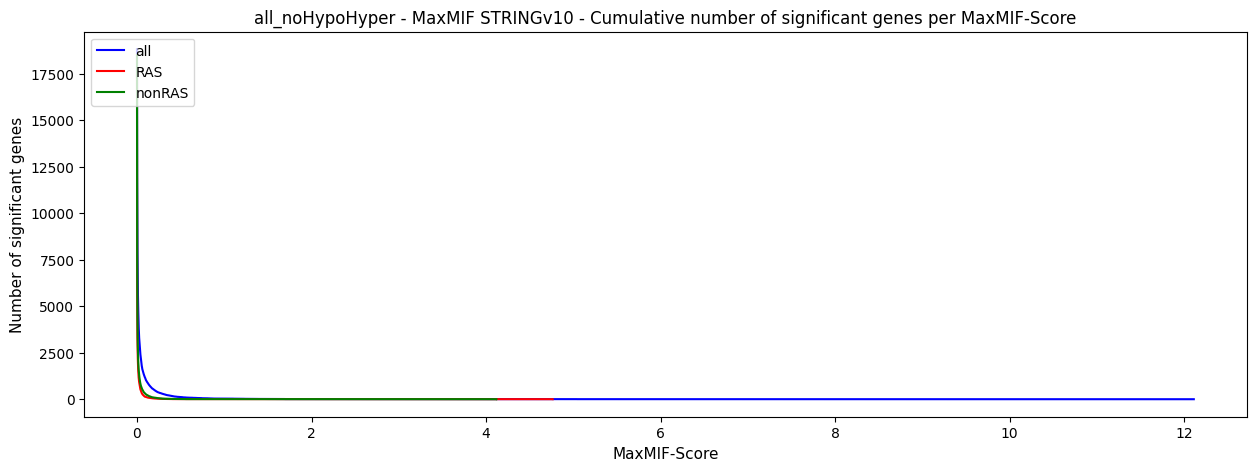

In [48]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MaxMIF STRINGv10 - Cumulative number of significant genes per MaxMIF-Score')
plt.plot(maxmifS_numGenes_sHigher.set_index('MaxMIF-Score'), label='all', color='blue')
plt.plot(maxmifS_numGenes_sHigher_RAS.set_index('MaxMIF-Score'), label='RAS', color='red')
plt.plot(maxmifS_numGenes_sHigher_nonRAS.set_index('MaxMIF-Score'), label='nonRAS', color='green')
plt.xlabel('MaxMIF-Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'maxmifS_cumulativeNumSignificantGenes_perMaxMIFScore_STRINGv10.png')
plt.show()

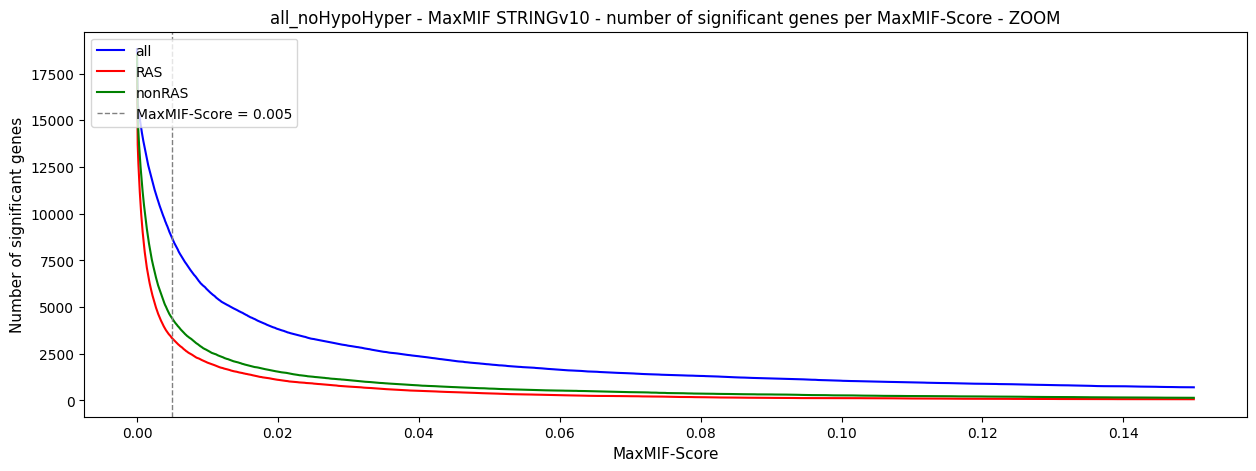

In [49]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MaxMIF STRINGv10 - number of significant genes per MaxMIF-Score - ZOOM')
plt.plot(maxmifS_numGenes_sHigher_zoom.set_index('MaxMIF-Score'), label='all', color='blue')
plt.plot(maxmifS_numGenes_sHigher_RAS_zoom.set_index('MaxMIF-Score'), label='RAS', color='red')
plt.plot(maxmifS_numGenes_sHigher_nonRAS_zoom.set_index('MaxMIF-Score'), label='nonRAS', color='green')
# plt.axvline(x=0.001, color='grey', linestyle='--', linewidth=1, label='MaxMIF-Score = 0.001')
plt.axvline(x=0.005, color='grey', linestyle='--', linewidth=1, label='MaxMIF-Score = 0.005')
# plt.axvline(x=0.04, color='grey', linestyle='-', linewidth=1, label='MaxMIF-Score = 0.04')
plt.xlabel('MaxMIF-Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig(data['plots___venn'] + 'maxmifS_cumulativeNumSignificantGenes_perMaxMIFScore_STRINGv10_onlyAll_ZOOM.png')
plt.show()

In [50]:
maxmifS_s_significant = 0.005

In [51]:
maxmifS_sGenes_all = set(maxmifS.loc[maxmifS['MaxMIF-Score'] > maxmifS_s_significant, 'GeneSymbol'])
maxmifS_sGenes_RAS = set(maxmifS_RAS.loc[maxmifS_RAS['MaxMIF-Score'] > maxmifS_s_significant, 'GeneSymbol'])
maxmifS_sGenes_nonRAS = set(maxmifS_nonRAS.loc[maxmifS_nonRAS['MaxMIF-Score'] > maxmifS_s_significant, 'GeneSymbol'])
maxmifS_sGenes_onlyRAS = set.difference(set(maxmifS_sGenes_RAS), set(maxmifS_sGenes_nonRAS))
maxmifS_sGenes_onlyNonRAS = set.difference(set(maxmifS_sGenes_nonRAS), set(maxmifS_sGenes_RAS))
maxmifS_sGenes_onlyRAS_onlyNonRAS = set.union(maxmifS_sGenes_onlyRAS, maxmifS_sGenes_onlyNonRAS)
len(maxmifS_sGenes_all), len(maxmifS_sGenes_RAS), len(maxmifS_sGenes_nonRAS), len(maxmifS_sGenes_onlyRAS)

(8682, 3330, 4397, 548)

## MUFFINN

In [52]:
muffinnMaxHN = pd.read_csv(data[f'muffinn___{dataset}___out_dir'] + '/DNmax_all_noHypoHyper.HumanNet', sep='\t', engine='python', comment='#')
muffinnMaxS = pd.read_csv(data[f'muffinn___{dataset}___out_dir'] + '/DNmax_all_noHypoHyper.STRINGv10', sep='\t', engine='python', comment='#')
muffinnSumHN = pd.read_csv(data[f'muffinn___{dataset}___out_dir'] + '/DNsum_all_noHypoHyper.HumanNet', sep='\t', engine='python', comment='#')
muffinnSumS = pd.read_csv(data[f'muffinn___{dataset}___out_dir'] + '/DNsum_all_noHypoHyper.STRINGv10', sep='\t', engine='python', comment='#')

muffinnMaxHN_RAS = pd.read_csv(data[f'muffinn___{dataset}_RAS___out_dir'] + '/DNmax_all_noHypoHyper_RAS.HumanNet', sep='\t', engine='python', comment='#')
muffinnMaxS_RAS = pd.read_csv(data[f'muffinn___{dataset}_RAS___out_dir'] + '/DNmax_all_noHypoHyper_RAS.STRINGv10', sep='\t', engine='python', comment='#')
muffinnSumHN_RAS = pd.read_csv(data[f'muffinn___{dataset}_RAS___out_dir'] + '/DNsum_all_noHypoHyper_RAS.HumanNet', sep='\t', engine='python', comment='#')
muffinnSumS_RAS = pd.read_csv(data[f'muffinn___{dataset}_RAS___out_dir'] + '/DNsum_all_noHypoHyper_RAS.STRINGv10', sep='\t', engine='python', comment='#')

muffinnMaxHN_nonRAS = pd.read_csv(data[f'muffinn___{dataset}_nonRAS___out_dir'] + '/DNmax_all_noHypoHyper_nonRAS.HumanNet', sep='\t', engine='python', comment='#')
muffinnMaxS_nonRAS = pd.read_csv(data[f'muffinn___{dataset}_nonRAS___out_dir'] + '/DNmax_all_noHypoHyper_nonRAS.STRINGv10', sep='\t', engine='python', comment='#')
muffinnSumHN_nonRAS = pd.read_csv(data[f'muffinn___{dataset}_nonRAS___out_dir'] + '/DNsum_all_noHypoHyper_nonRAS.HumanNet', sep='\t', engine='python', comment='#')
muffinnSumS_nonRAS = pd.read_csv(data[f'muffinn___{dataset}_nonRAS___out_dir'] + '/DNsum_all_noHypoHyper_nonRAS.STRINGv10', sep='\t', engine='python', comment='#')

### MAX - HumanNet

In [53]:
muffinnMaxHN_numGenes_sHigher = pd.DataFrame(
    [(i, len(muffinnMaxHN.loc[muffinnMaxHN['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnMaxHN['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnMaxHN_numGenes_sHigher_RAS = pd.DataFrame(
    [(i, len(muffinnMaxHN_RAS.loc[muffinnMaxHN_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnMaxHN_RAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnMaxHN_numGenes_sHigher_nonRAS = pd.DataFrame(
    [(i, len(muffinnMaxHN_nonRAS.loc[muffinnMaxHN_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnMaxHN_nonRAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)

muffinnMaxHN_numGenes_sHigher_zoom = pd.DataFrame(
    [(i, len(muffinnMaxHN.loc[muffinnMaxHN['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnMaxHN_numGenes_sHigher_RAS_zoom = pd.DataFrame(
    [(i, len(muffinnMaxHN_RAS.loc[muffinnMaxHN_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnMaxHN_numGenes_sHigher_nonRAS_zoom = pd.DataFrame(
    [(i, len(muffinnMaxHN_nonRAS.loc[muffinnMaxHN_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

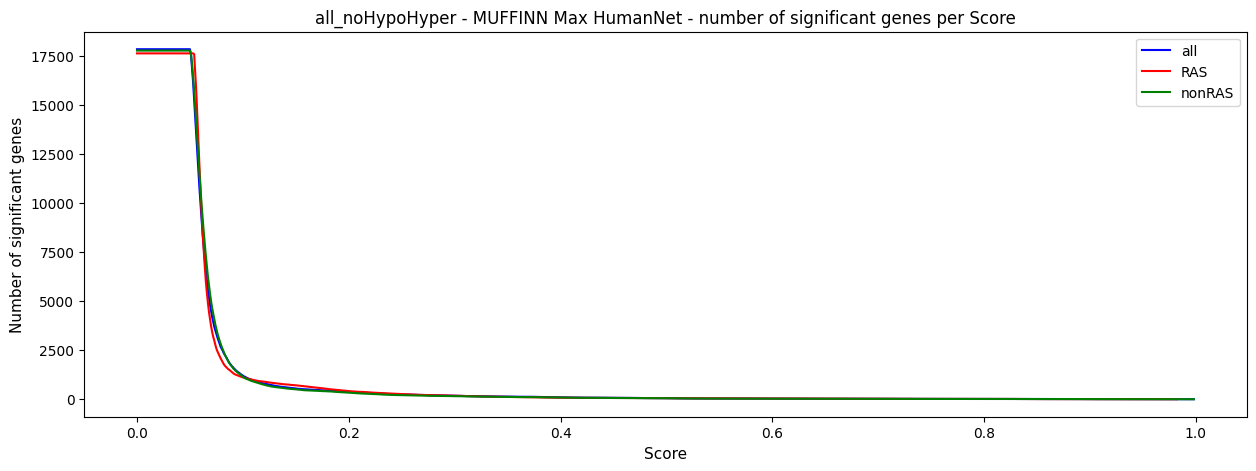

In [54]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Max HumanNet - number of significant genes per Score')
plt.plot(muffinnMaxHN_numGenes_sHigher.set_index('Score'), label='all', color='blue')
plt.plot(muffinnMaxHN_numGenes_sHigher_RAS.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnMaxHN_numGenes_sHigher_nonRAS.set_index('Score'), label='nonRAS', color='green')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnMaxHN_cumulativeNumSignificantGenes_perScore_HumanNet.png')
plt.show()

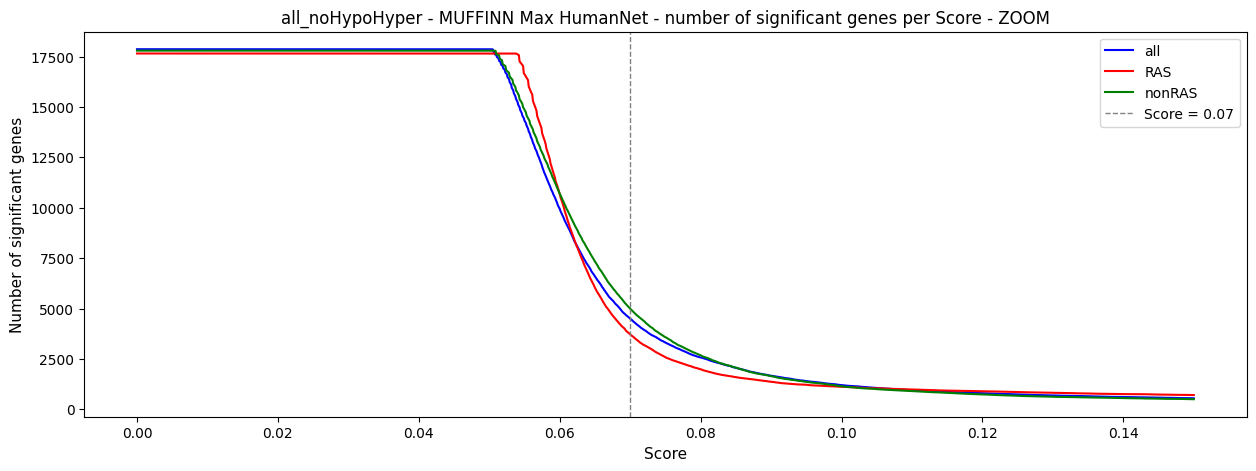

In [55]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Max HumanNet - number of significant genes per Score - ZOOM')
plt.plot(muffinnMaxHN_numGenes_sHigher_zoom.set_index('Score'), label='all', color='blue')
plt.plot(muffinnMaxHN_numGenes_sHigher_RAS_zoom.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnMaxHN_numGenes_sHigher_nonRAS_zoom.set_index('Score'), label='nonRAS', color='green')
# plt.axvline(x=0.06, color='grey', linestyle='--', linewidth=1, label='Score = 0.06')
plt.axvline(x=0.07, color='grey', linestyle='--', linewidth=1, label='Score = 0.07')
# plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='Score = 0.1')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnMaxHN_cumulativeNumSignificantGenes_perScore_HumanNet_ZOOM.png')
plt.show()

In [56]:
muffinnMaxHN_s_significant = 0.07

In [57]:
muffinnMaxHN_sGenes_all = set(muffinnMaxHN.loc[muffinnMaxHN['Score'] > muffinnMaxHN_s_significant, 'Gene_Symbol'])
muffinnMaxHN_sGenes_RAS = set(muffinnMaxHN_RAS.loc[muffinnMaxHN_RAS['Score'] > muffinnMaxHN_s_significant, 'Gene_Symbol'])
muffinnMaxHN_sGenes_nonRAS = set(muffinnMaxHN_nonRAS.loc[muffinnMaxHN_nonRAS['Score'] > muffinnMaxHN_s_significant, 'Gene_Symbol'])
muffinnMaxHN_sGenes_onlyRAS = set.difference(set(muffinnMaxHN_sGenes_RAS), set(muffinnMaxHN_sGenes_nonRAS))
muffinnMaxHN_sGenes_onlyNonRAS = set.difference(set(muffinnMaxHN_sGenes_nonRAS), set(muffinnMaxHN_sGenes_RAS))
muffinnMaxHN_sGenes_onlyRAS_onlyNonRAS = set.union(muffinnMaxHN_sGenes_onlyRAS, muffinnMaxHN_sGenes_onlyNonRAS)
len(muffinnMaxHN_sGenes_all), len(muffinnMaxHN_sGenes_RAS), len(muffinnMaxHN_sGenes_nonRAS), len(muffinnMaxHN_sGenes_onlyRAS), len(muffinnMaxHN_sGenes_onlyNonRAS), len(muffinnMaxHN_sGenes_onlyRAS_onlyNonRAS)

(4498, 3717, 4993, 340, 1616, 1956)

### MAX - STRINGv10

In [58]:
muffinnMaxS_numGenes_sHigher = pd.DataFrame(
    [(i, len(muffinnMaxS.loc[muffinnMaxS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnMaxS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnMaxS_numGenes_sHigher_RAS = pd.DataFrame(
    [(i, len(muffinnMaxS_RAS.loc[muffinnMaxS_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnMaxS_RAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnMaxS_numGenes_sHigher_nonRAS = pd.DataFrame(
    [(i, len(muffinnMaxS_nonRAS.loc[muffinnMaxS_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnMaxS_nonRAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)

muffinnMaxS_numGenes_sHigher_zoom = pd.DataFrame(
    [(i, len(muffinnMaxS.loc[muffinnMaxS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.25 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnMaxS_numGenes_sHigher_RAS_zoom = pd.DataFrame(
    [(i, len(muffinnMaxS_RAS.loc[muffinnMaxS_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.25 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnMaxS_numGenes_sHigher_nonRAS_zoom = pd.DataFrame(
    [(i, len(muffinnMaxS_nonRAS.loc[muffinnMaxS_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.25 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

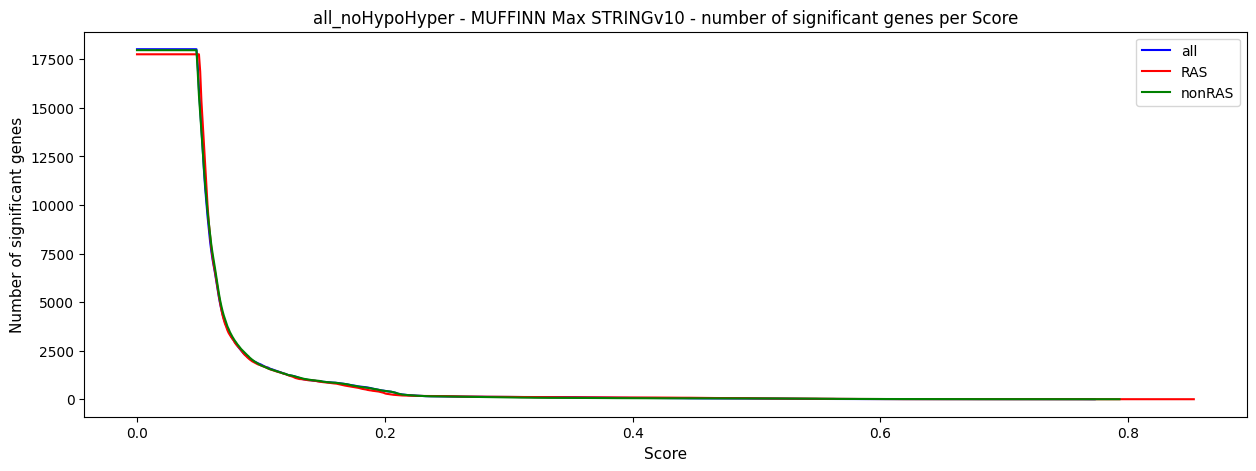

In [59]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Max STRINGv10 - number of significant genes per Score')
plt.plot(muffinnMaxS_numGenes_sHigher.set_index('Score'), label='all', color='blue')
plt.plot(muffinnMaxS_numGenes_sHigher_RAS.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnMaxS_numGenes_sHigher_nonRAS.set_index('Score'), label='nonRAS', color='green')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnMaxS_cumulativeNumSignificantGenes_perScore_STRINGv10.png')
plt.show()

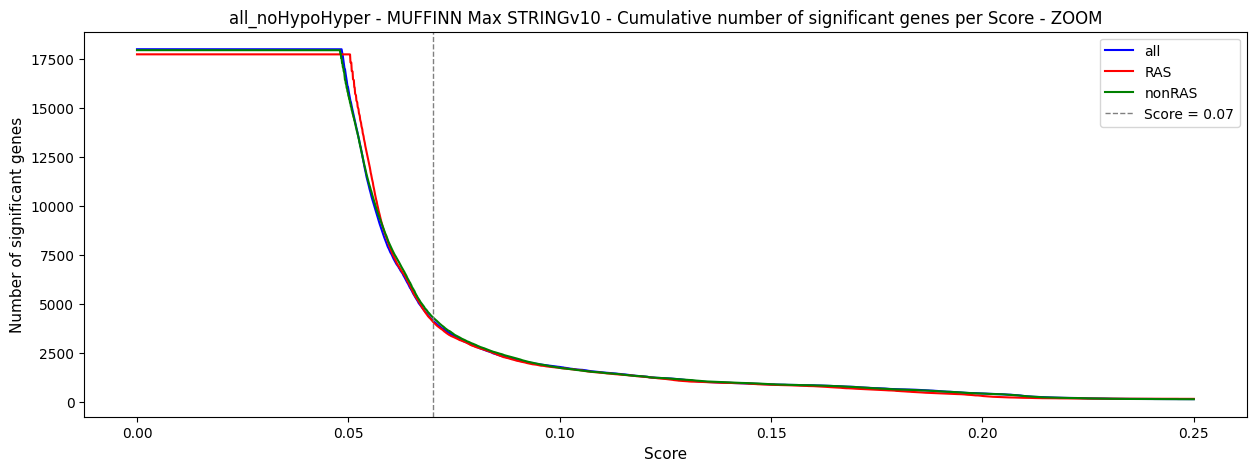

In [60]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Max STRINGv10 - Cumulative number of significant genes per Score - ZOOM')
plt.plot(muffinnMaxS_numGenes_sHigher_zoom.set_index('Score'), label='all', color='blue')
plt.plot(muffinnMaxS_numGenes_sHigher_RAS_zoom.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnMaxS_numGenes_sHigher_nonRAS_zoom.set_index('Score'), label='nonRAS', color='green')
# plt.axvline(x=0.06, color='grey', linestyle='--', linewidth=1, label='Score = 0.06')
plt.axvline(x=0.07, color='grey', linestyle='--', linewidth=1, label='Score = 0.07')
# plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='Score = 0.1')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnMaxS_cumulativeNumSignificantGenes_perScore_STRINGv10_ZOOM.png')
plt.show()

In [61]:
muffinnMaxS_s_significant = 0.07

In [62]:
muffinnMaxS_sGenes_all = set(muffinnMaxS.loc[muffinnMaxS['Score'] > muffinnMaxS_s_significant, 'Gene_Symbol'])
muffinnMaxS_sGenes_RAS = set(muffinnMaxS_RAS.loc[muffinnMaxS_RAS['Score'] > muffinnMaxS_s_significant, 'Gene_Symbol'])
muffinnMaxS_sGenes_nonRAS = set(muffinnMaxS_nonRAS.loc[muffinnMaxS_nonRAS['Score'] > muffinnMaxS_s_significant, 'Gene_Symbol'])
muffinnMaxS_sGenes_onlyRAS = set.difference(set(muffinnMaxS_sGenes_RAS), set(muffinnMaxS_sGenes_nonRAS))
muffinnMaxS_sGenes_onlyNonRAS = set.difference(set(muffinnMaxS_sGenes_nonRAS), set(muffinnMaxS_sGenes_RAS))
muffinnMaxS_sGenes_onlyRAS_onlyNonRAS = set.union(muffinnMaxS_sGenes_onlyRAS, muffinnMaxS_sGenes_onlyNonRAS)
len(muffinnMaxS_sGenes_all), len(muffinnMaxS_sGenes_RAS), len(muffinnMaxS_sGenes_nonRAS), len(muffinnMaxS_sGenes_onlyRAS), len(muffinnMaxS_sGenes_onlyNonRAS), len(muffinnMaxS_sGenes_onlyRAS_onlyNonRAS)

(4161, 4102, 4322, 243, 463, 706)

### SUM - HumanNet

In [63]:
muffinnSumHN_numGenes_sHigher = pd.DataFrame(
    [(i, len(muffinnSumHN.loc[muffinnSumHN['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnSumHN['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnSumHN_numGenes_sHigher_RAS = pd.DataFrame(
    [(i, len(muffinnSumHN_RAS.loc[muffinnSumHN_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnSumHN_RAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnSumHN_numGenes_sHigher_nonRAS = pd.DataFrame(
    [(i, len(muffinnSumHN_nonRAS.loc[muffinnSumHN_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnSumHN_nonRAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)

muffinnSumHN_numGenes_sHigher_zoom = pd.DataFrame(
    [(i, len(muffinnSumHN.loc[muffinnSumHN['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnSumHN_numGenes_sHigher_RAS_zoom = pd.DataFrame(
    [(i, len(muffinnSumHN_RAS.loc[muffinnSumHN_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnSumHN_numGenes_sHigher_nonRAS_zoom = pd.DataFrame(
    [(i, len(muffinnSumHN_nonRAS.loc[muffinnSumHN_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.15 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

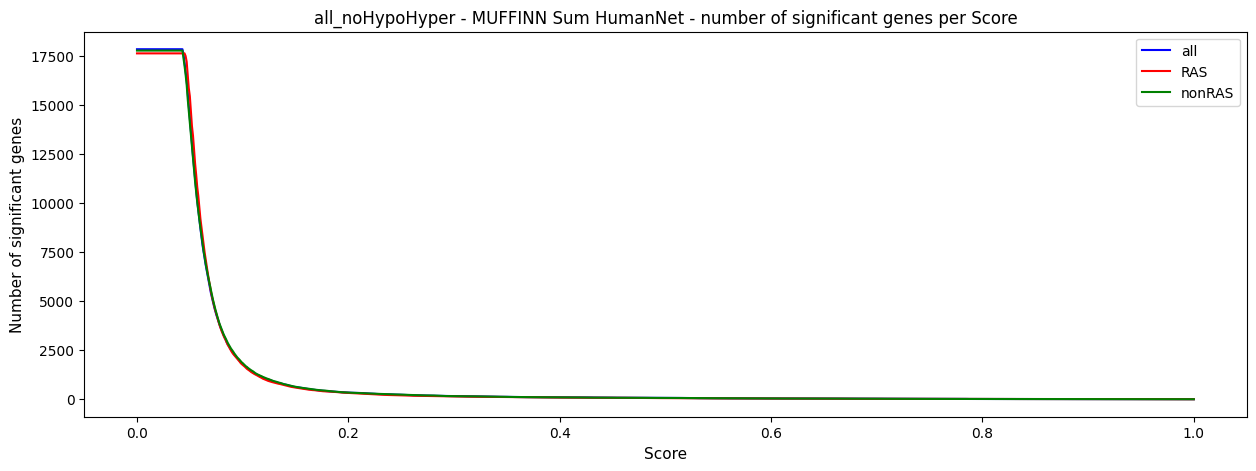

In [64]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Sum HumanNet - number of significant genes per Score')
plt.plot(muffinnSumHN_numGenes_sHigher.set_index('Score'), label='all', color='blue')
plt.plot(muffinnSumHN_numGenes_sHigher_RAS.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnSumHN_numGenes_sHigher_nonRAS.set_index('Score'), label='nonRAS', color='green')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnSumHN_cumulativeNumSignificantGenes_perScore_HumanNet.png')
plt.show()

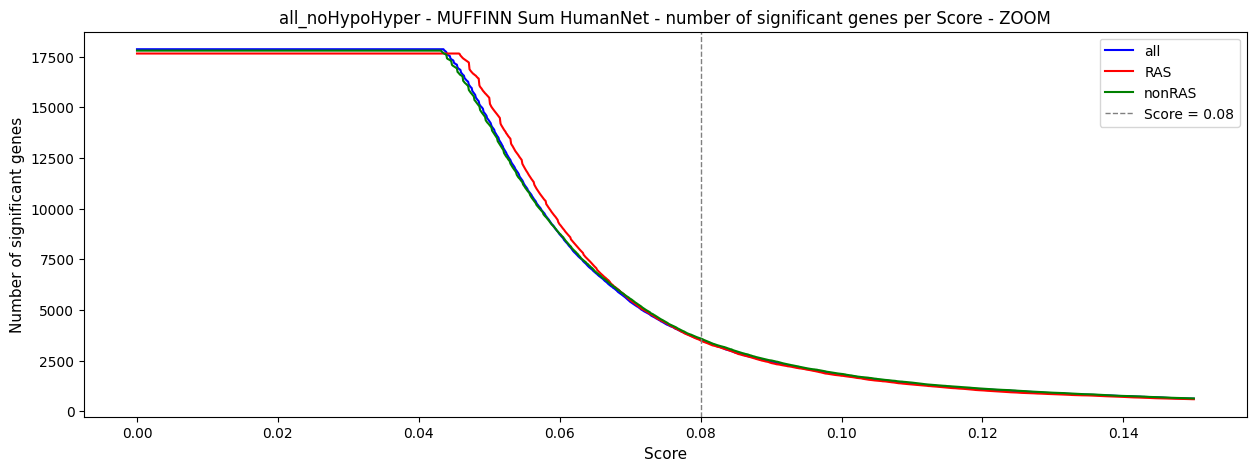

In [65]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Sum HumanNet - number of significant genes per Score - ZOOM')
plt.plot(muffinnSumHN_numGenes_sHigher_zoom.set_index('Score'), label='all', color='blue')
plt.plot(muffinnSumHN_numGenes_sHigher_RAS_zoom.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnSumHN_numGenes_sHigher_nonRAS_zoom.set_index('Score'), label='nonRAS', color='green')
# plt.axvline(x=0.06, color='grey', linestyle='--', linewidth=1, label='Score = 0.06')
plt.axvline(x=0.08, color='grey', linestyle='--', linewidth=1, label='Score = 0.08')
# plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='Score = 0.1')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnSumHN_cumulativeNumSignificantGenes_perScore_HumanNet_ZOOM.png')
plt.show()

In [66]:
muffinnSumHN_s_significant = 0.08

In [67]:
muffinnSumHN_sGenes_all = set(muffinnSumHN.loc[muffinnSumHN['Score'] > muffinnSumHN_s_significant, 'Gene_Symbol'])
muffinnSumHN_sGenes_RAS = set(muffinnSumHN_RAS.loc[muffinnSumHN_RAS['Score'] > muffinnSumHN_s_significant, 'Gene_Symbol'])
muffinnSumHN_sGenes_nonRAS = set(muffinnSumHN_nonRAS.loc[muffinnSumHN_nonRAS['Score'] > muffinnSumHN_s_significant, 'Gene_Symbol'])
muffinnSumHN_sGenes_onlyRAS = set.difference(set(muffinnSumHN_sGenes_RAS), set(muffinnSumHN_sGenes_nonRAS))
muffinnSumHN_sGenes_onlyNonRAS = set.difference(set(muffinnSumHN_sGenes_nonRAS), set(muffinnSumHN_sGenes_RAS))
muffinnSumHN_sGenes_onlyRAS_onlyNonRAS = set.union(muffinnSumHN_sGenes_onlyRAS, muffinnSumHN_sGenes_onlyNonRAS)
len(muffinnSumHN_sGenes_all), len(muffinnSumHN_sGenes_RAS), len(muffinnSumHN_sGenes_nonRAS), len(muffinnSumHN_sGenes_onlyRAS), len(muffinnSumHN_sGenes_onlyNonRAS), len(muffinnSumHN_sGenes_onlyRAS_onlyNonRAS)

(3539, 3489, 3594, 523, 628, 1151)

### SUM - STRINGv10

In [68]:
muffinnSumS_numGenes_sHigher = pd.DataFrame(
    [(i, len(muffinnSumS.loc[muffinnSumS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnSumS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnSumS_numGenes_sHigher_RAS = pd.DataFrame(
    [(i, len(muffinnSumS_RAS.loc[muffinnSumS_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnSumS_RAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)
muffinnSumS_numGenes_sHigher_nonRAS = pd.DataFrame(
    [(i, len(muffinnSumS_nonRAS.loc[muffinnSumS_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, muffinnSumS_nonRAS['Score'].max() + qfreq, qfreq)],
    columns=['Score', 'numGenes']
)

muffinnSumS_numGenes_sHigher_zoom = pd.DataFrame(
    [(i, len(muffinnSumS.loc[muffinnSumS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.25 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnSumS_numGenes_sHigher_RAS_zoom = pd.DataFrame(
    [(i, len(muffinnSumS_RAS.loc[muffinnSumS_RAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.25 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

muffinnSumS_numGenes_sHigher_nonRAS_zoom = pd.DataFrame(
    [(i, len(muffinnSumS_nonRAS.loc[muffinnSumS_nonRAS['Score'] >= i, 'Gene_Symbol'])) for i in np.arange(0, 0.25 + 0.0001, 0.0001)],
    columns=['Score', 'numGenes']
)

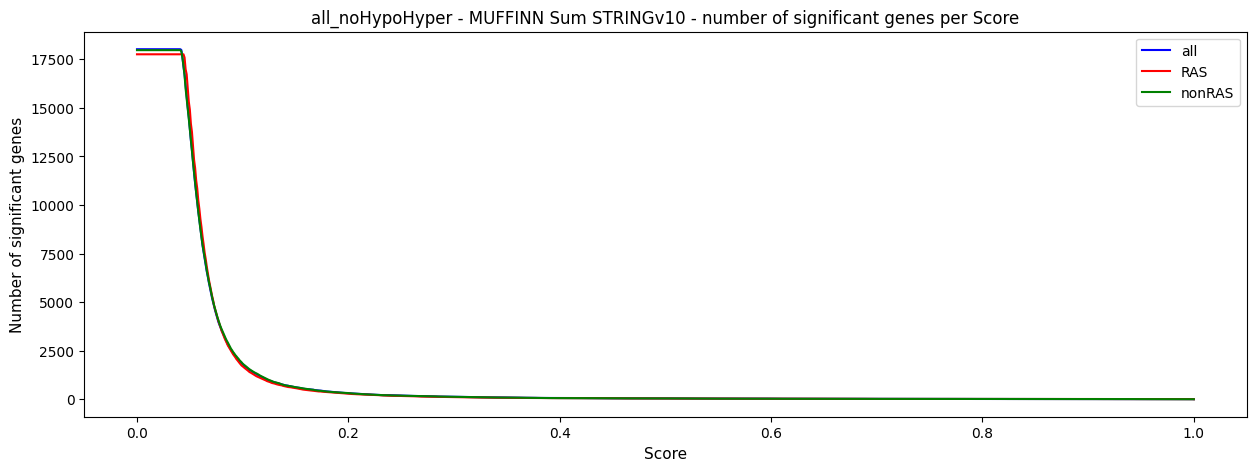

In [69]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Sum STRINGv10 - number of significant genes per Score')
plt.plot(muffinnSumS_numGenes_sHigher.set_index('Score'), label='all', color='blue')
plt.plot(muffinnSumS_numGenes_sHigher_RAS.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnSumS_numGenes_sHigher_nonRAS.set_index('Score'), label='nonRAS', color='green')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnSumS_cumulativeNumSignificantGenes_perScore_STRINGv10.png')
plt.show()

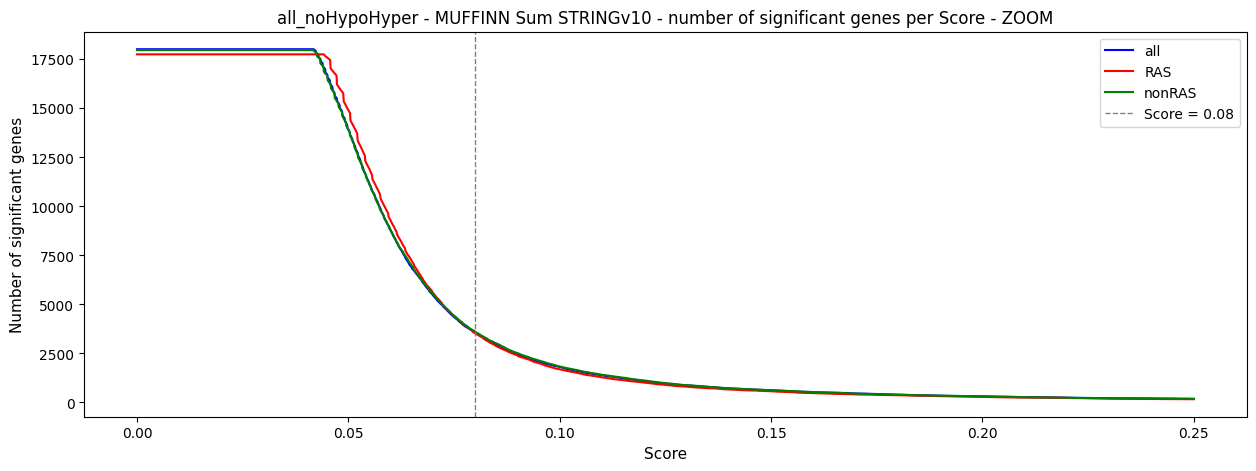

In [70]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - MUFFINN Sum STRINGv10 - number of significant genes per Score - ZOOM')
plt.plot(muffinnSumS_numGenes_sHigher_zoom.set_index('Score'), label='all', color='blue')
plt.plot(muffinnSumS_numGenes_sHigher_RAS_zoom.set_index('Score'), label='RAS', color='red')
plt.plot(muffinnSumS_numGenes_sHigher_nonRAS_zoom.set_index('Score'), label='nonRAS', color='green')
# plt.axvline(x=0.06, color='grey', linestyle='--', linewidth=1, label='Score = 0.06')
plt.axvline(x=0.08, color='grey', linestyle='--', linewidth=1, label='Score = 0.08')
# plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='Score = 0.1')
plt.xlabel('Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'muffinnSumS_cumulativeNumSignificantGenes_perScore_STRINGv10_ZOOM.png')
plt.show()

In [71]:
muffinnSumS_s_significant = 0.08

In [72]:
muffinnSumS_sGenes_all = set(muffinnSumS.loc[muffinnSumS['Score'] > muffinnSumS_s_significant, 'Gene_Symbol'])
muffinnSumS_sGenes_RAS = set(muffinnSumS_RAS.loc[muffinnSumS_RAS['Score'] > muffinnSumS_s_significant, 'Gene_Symbol'])
muffinnSumS_sGenes_nonRAS = set(muffinnSumS_nonRAS.loc[muffinnSumS_nonRAS['Score'] > muffinnSumS_s_significant, 'Gene_Symbol'])
muffinnSumS_sGenes_onlyRAS = set.difference(set(muffinnSumS_sGenes_RAS), set(muffinnSumS_sGenes_nonRAS))
muffinnSumS_sGenes_onlyNonRAS = set.difference(set(muffinnSumS_sGenes_nonRAS), set(muffinnSumS_sGenes_RAS))
muffinnSumS_sGenes_onlyRAS_onlyNonRAS = set.union(muffinnSumS_sGenes_onlyRAS, muffinnSumS_sGenes_onlyNonRAS)
len(muffinnSumS_sGenes_all), len(muffinnSumS_sGenes_RAS), len(muffinnSumS_sGenes_nonRAS), len(muffinnSumS_sGenes_onlyRAS), len(muffinnSumS_sGenes_onlyNonRAS), len(muffinnSumS_sGenes_onlyRAS_onlyNonRAS)

(3551, 3530, 3616, 545, 631, 1176)

## HotNet2

In [73]:
with open(data[f'hotnet2___{dataset}___out_dir'] + 'results/consensus/viz-data.json') as f:
    hotnet2_consensus_all = json.load(f)
with open(data[f'hotnet2___{dataset}_RAS___out_dir'] + 'results/consensus/viz-data.json') as f:
    hotnet2_consensus_RAS = json.load(f)
with open(data[f'hotnet2___{dataset}_nonRAS___out_dir'] + 'results/consensus/viz-data.json') as f:
    hotnet2_consensus_nonRAS = json.load(f)

In [74]:
def getSubnetworks(consensus):
    rows = []
    for subnetwork in consensus['subnetworks']['0']:
        heat = 0
        genes = []
        for node in subnetwork['nodes']:
            genes.append(node['name'])
            heat += node['value']
        rows.append({'genes': ', '.join(genes), 'size': len(genes), 'heat': heat})
    return pd.DataFrame(rows).sort_values('heat', ascending=False)

hotnet2_all = getSubnetworks(hotnet2_consensus_all)
hotnet2_RAS = getSubnetworks(hotnet2_consensus_RAS)
hotnet2_nonRAS = getSubnetworks(hotnet2_consensus_nonRAS)

In [75]:
hotnet2_numNetworks_heatGrater_all = pd.DataFrame(
    [(i, len(hotnet2_all.loc[hotnet2_all['heat'] >= i, 'genes'])) for i in hotnet2_all['heat'].unique()],
    columns=['heat', 'numNetworks']
)
hotnet2_numNetworks_heatGrater_RAS = pd.DataFrame(
    [(i, len(hotnet2_RAS.loc[hotnet2_RAS['heat'] >= i, 'genes'])) for i in hotnet2_RAS['heat'].unique()],
    columns=['heat', 'numNetworks']
)
hotnet2_numNetworks_heatGrater_nonRAS = pd.DataFrame(
    [(i, len(hotnet2_nonRAS.loc[hotnet2_nonRAS['heat'] >= i, 'genes'])) for i in hotnet2_nonRAS['heat'].unique()],
    columns=['heat', 'numNetworks']
)

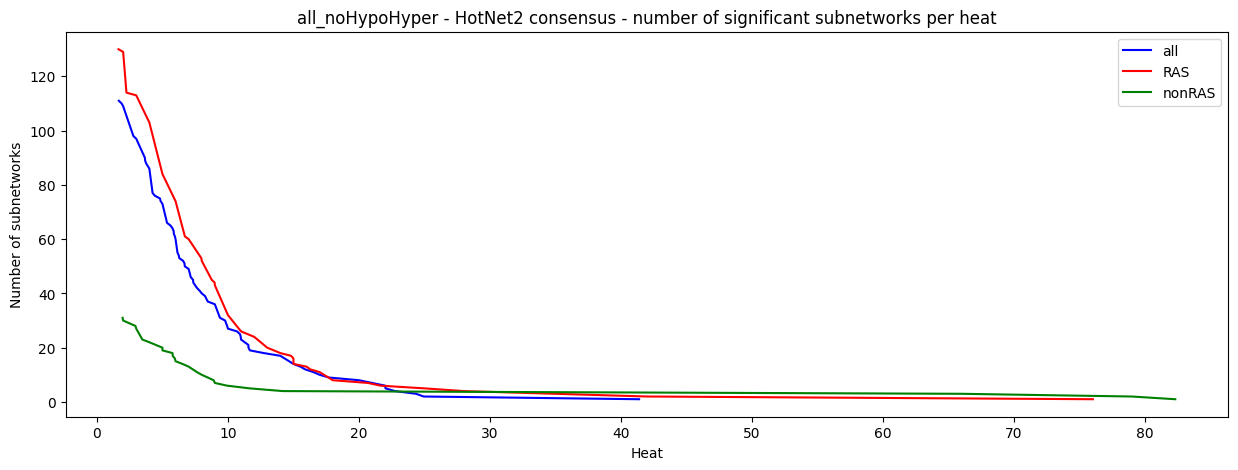

In [76]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - HotNet2 consensus - number of significant subnetworks per heat')
plt.plot(hotnet2_numNetworks_heatGrater_all.set_index('heat'), label='all', color='blue')
plt.plot(hotnet2_numNetworks_heatGrater_RAS.set_index('heat'), label='RAS', color='red')
plt.plot(hotnet2_numNetworks_heatGrater_nonRAS.set_index('heat'), label='nonRAS', color='green')
plt.xlabel('Heat')
plt.ylabel('Number of subnetworks')
plt.legend(loc='upper right', fontsize=10)
plt.savefig(data['plots___venn'] + 'hotnet2_cumulativeNumSignificantNetworks.png')
plt.show()

In [77]:
len(hotnet2_all), len(hotnet2_RAS), len(hotnet2_nonRAS)

(111, 130, 31)

In [78]:
# array with all genes in the subnetworks
hotnet2_sGenes_all = set()
for genes_all in hotnet2_all['genes']:
    hotnet2_sGenes_all.update(genes_all.split(', '))
hotnet2_sGenes_RAS = set()
for genes_all in hotnet2_RAS['genes']:
    hotnet2_sGenes_RAS.update(genes_all.split(', '))
hotnet2_sGenes_nonRAS = set()
for genes_all in hotnet2_nonRAS['genes']:
    hotnet2_sGenes_nonRAS.update(genes_all.split(', '))

hotnet2_sGenes_onlyRAS = hotnet2_sGenes_RAS.difference(hotnet2_sGenes_nonRAS)
hotnet2_sGenes_onlyNonRAS = hotnet2_sGenes_nonRAS.difference(hotnet2_sGenes_RAS)
hotnet2_sGenes_onlyRAS_onlyNonRAS = set.union(hotnet2_sGenes_onlyRAS, hotnet2_sGenes_onlyNonRAS)

In [79]:
len(hotnet2_sGenes_all), len(hotnet2_sGenes_RAS), len(hotnet2_sGenes_nonRAS), len(hotnet2_sGenes_onlyRAS), len(hotnet2_sGenes_onlyNonRAS), len(hotnet2_sGenes_onlyRAS_onlyNonRAS)

(914, 1084, 400, 865, 181, 1046)

# Visualizations

## venn ALL

In [80]:
genes_all = {}

In [81]:
genes_all[f'mutsig_q{mutsig_q_significant}'] = set(mutsig_q_sGenes_all)
genes_all[f'driverml_q{driverml_q_significant}'] = set(driverml_q_sGenes_all)
genes_all[f'mutpanning_q{mutpanning_q_significant}'] = set(mutpanning_q_sGenes_all)
genes_all[f'netsig_p{netsig_p_significant}'] = set(netsig_p_sGenes_all)
genes_all[f'maxmif_HNs{maxmifHN_s_significant}_Ss{maxmifS_s_significant}'] = set.union(set(maxmifHN_sGenes_all), set(maxmifS_sGenes_all))
genes_all[f'muffinn_maxHNs{muffinnMaxHN_s_significant}_maxSs{muffinnMaxS_s_significant}_sumHNs{muffinnSumHN_s_significant}_sumSs{muffinnSumS_s_significant}'] = set.union(set(muffinnMaxHN_sGenes_all), set(muffinnMaxS_sGenes_all), set(muffinnSumHN_sGenes_all), set(muffinnSumS_sGenes_all))
genes_all[f'hotnet2'] = set(hotnet2_sGenes_all)

In [82]:
matrix = pd.DataFrame(index=genes_all.keys(), columns=genes_all.keys())
for i in genes_all.keys():
    for j in genes_all.keys():
        intersection = len(genes_all[i].intersection(genes_all[j]))
        matrix.at[i, j] = f"{intersection/len(genes_all[i])*100:.0f}%"
matrix

,mutsig_q1,driverml_q0.5,mutpanning_q1,netsig_p1,maxmif_HNs0.0007_Ss0.005,muffinn_maxHNs0.07_maxSs0.07_sumHNs0.08_sumSs0.08,hotnet2
mutsig_q1,100%,41%,26%,46%,70%,47%,3%
driverml_q0.5,18%,100%,39%,45%,77%,54%,5%
mutpanning_q1,8%,25%,100%,41%,52%,35%,5%
netsig_p1,14%,32%,45%,100%,72%,55%,6%
maxmif_HNs0.0007_Ss0.005,17%,42%,44%,56%,100%,62%,6%
muffinn_maxHNs0.07_maxSs0.07_sumHNs0.08_sumSs0.08,17%,43%,44%,63%,91%,100%,6%
hotnet2,8%,34%,52%,60%,69%,52%,100%


In [83]:
matrix.index

Index(['mutsig_q1', 'driverml_q0.5', 'mutpanning_q1', 'netsig_p1',
       'maxmif_HNs0.0007_Ss0.005',
       'muffinn_maxHNs0.07_maxSs0.07_sumHNs0.08_sumSs0.08', 'hotnet2'],
      dtype='object')

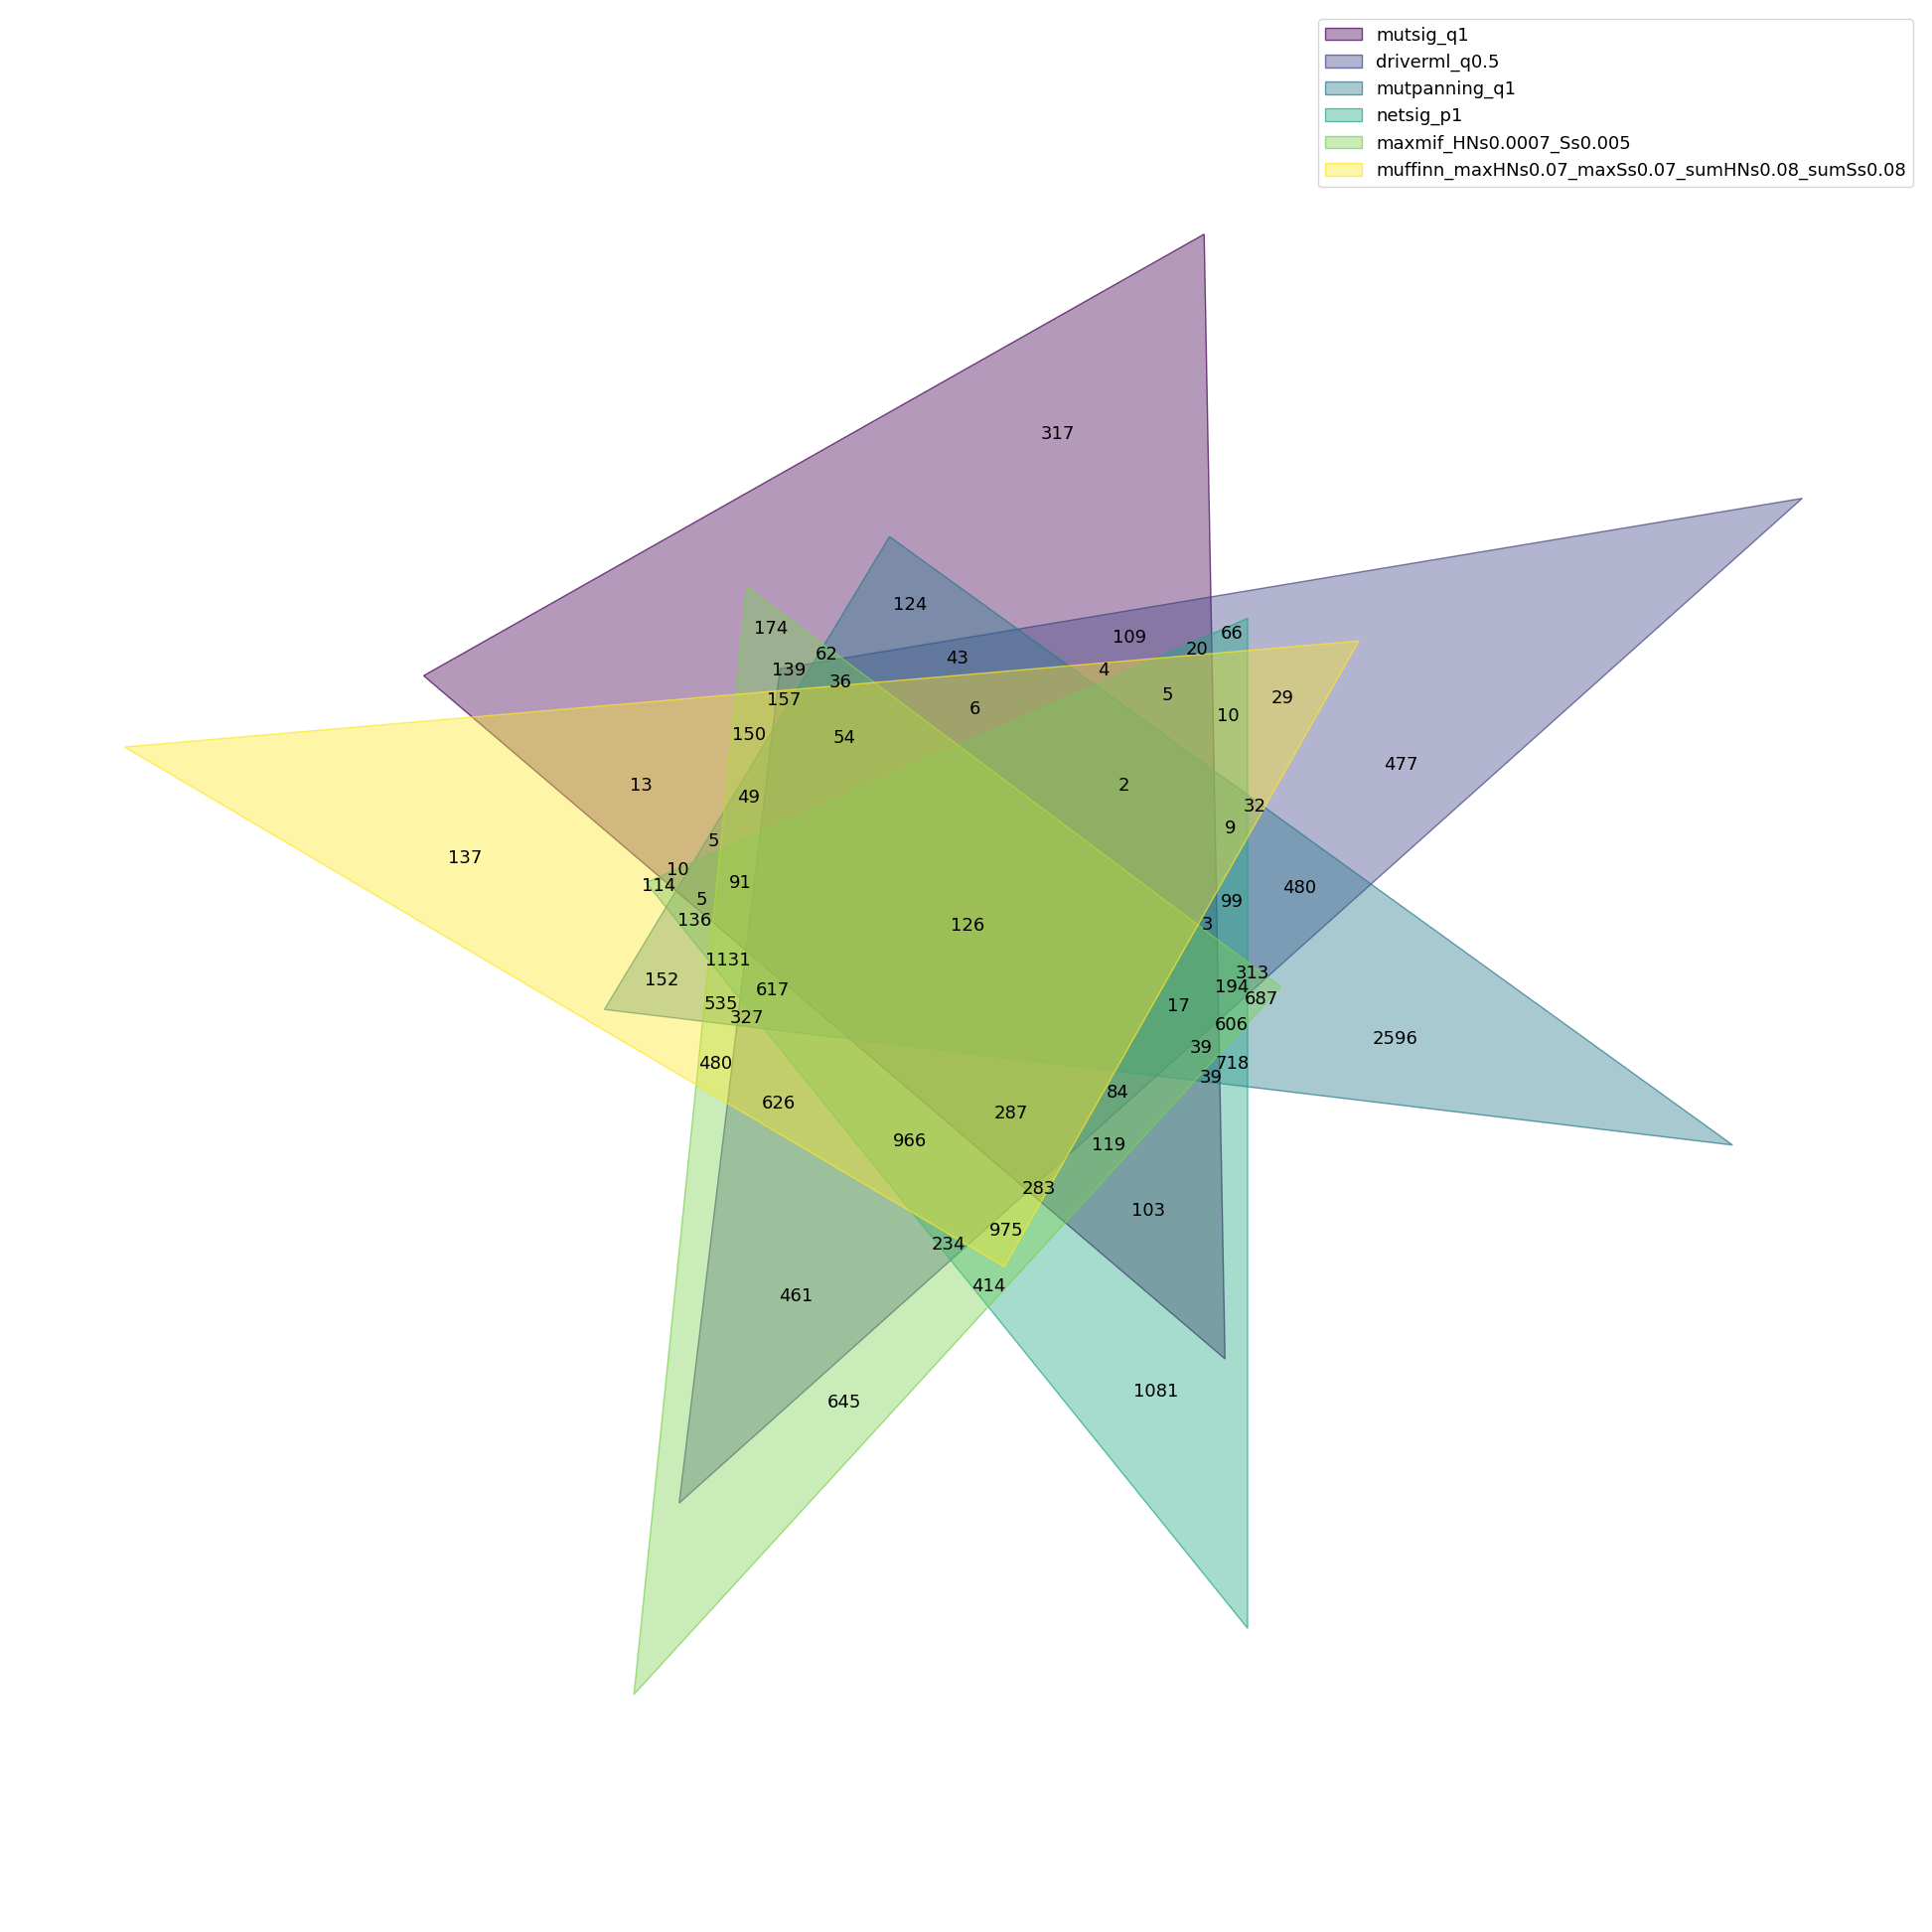

In [84]:
fig, ax = plt.subplots(figsize=(25, 25))
venn({k: v for k, v in genes_all.items() if any(m in k for m in {'mutsig', 'driverml', 'mutpanning', 'netsig', 'maxmif', 'muffinn'})}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_all.png')

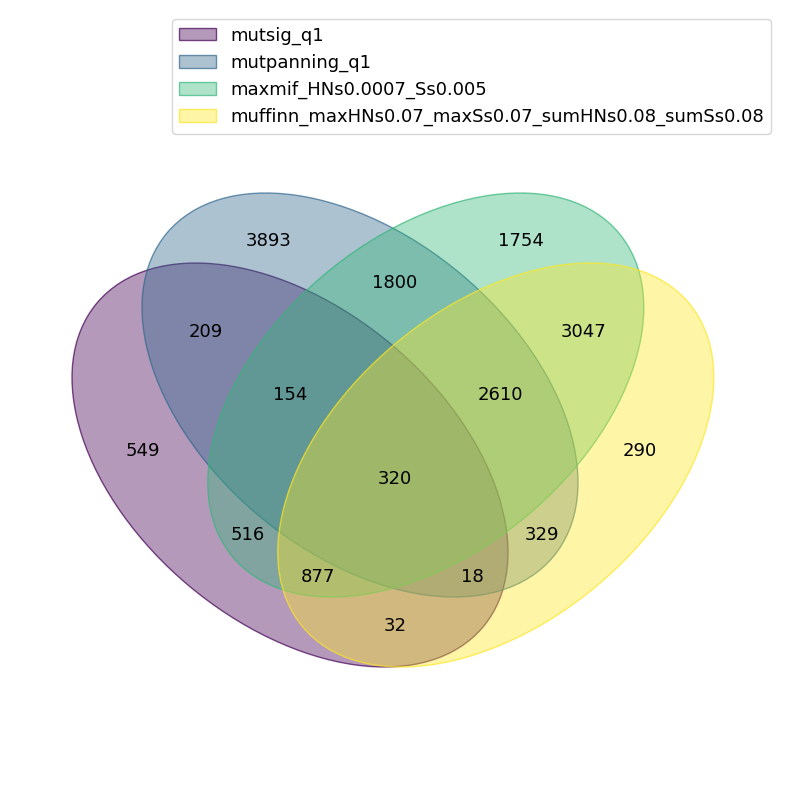

In [85]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_all.items() if any(m in k for m in {'mutsig', 'mutpanning', 'maxmif', 'muffinn'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_all_mutsig_mutpanning_maxmif_muffinn.png')

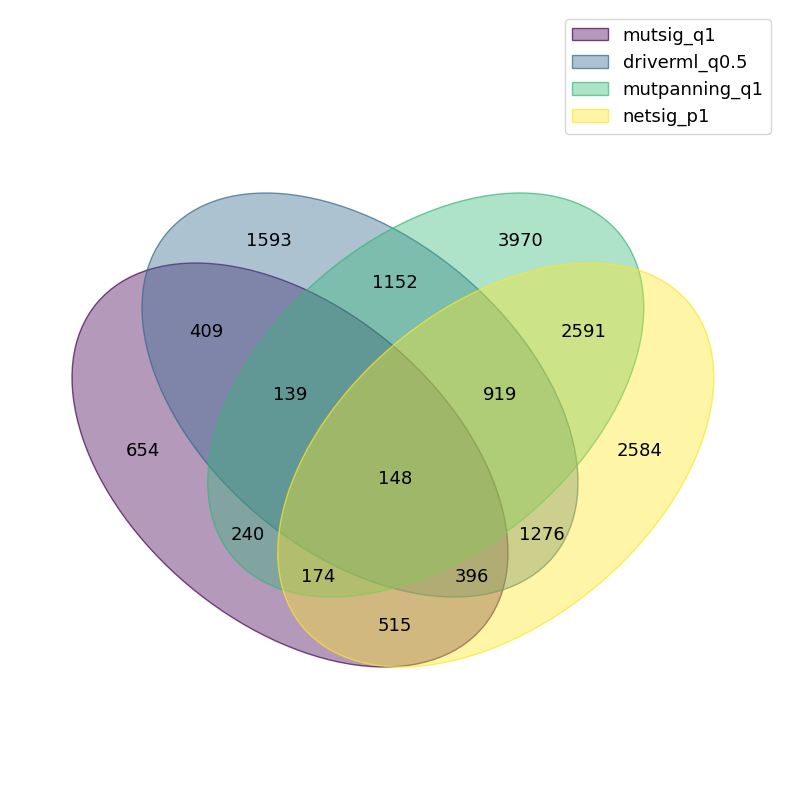

In [86]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_all.items() if any(m in k for m in {'mutsig', 'driverml', 'mutpanning', 'netsig'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_all_mutsig_driverml_mutpanning_netsig.png')

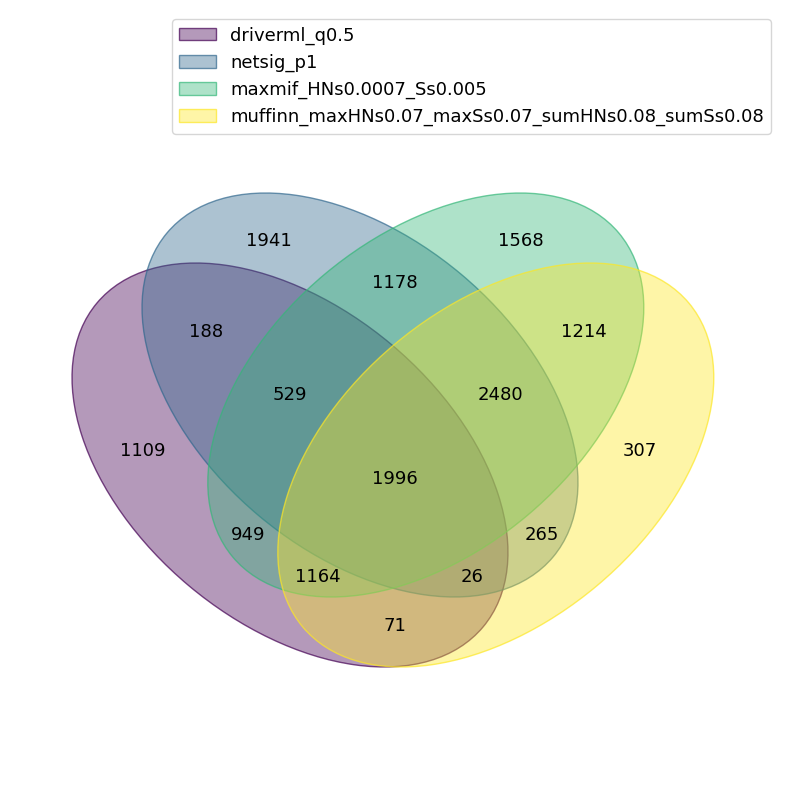

In [87]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_all.items() if any(m in k for m in {'driverml', 'netsig', 'maxmif', 'muffinn'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_all_driverml_netsig_maxmif_muffinn.png')

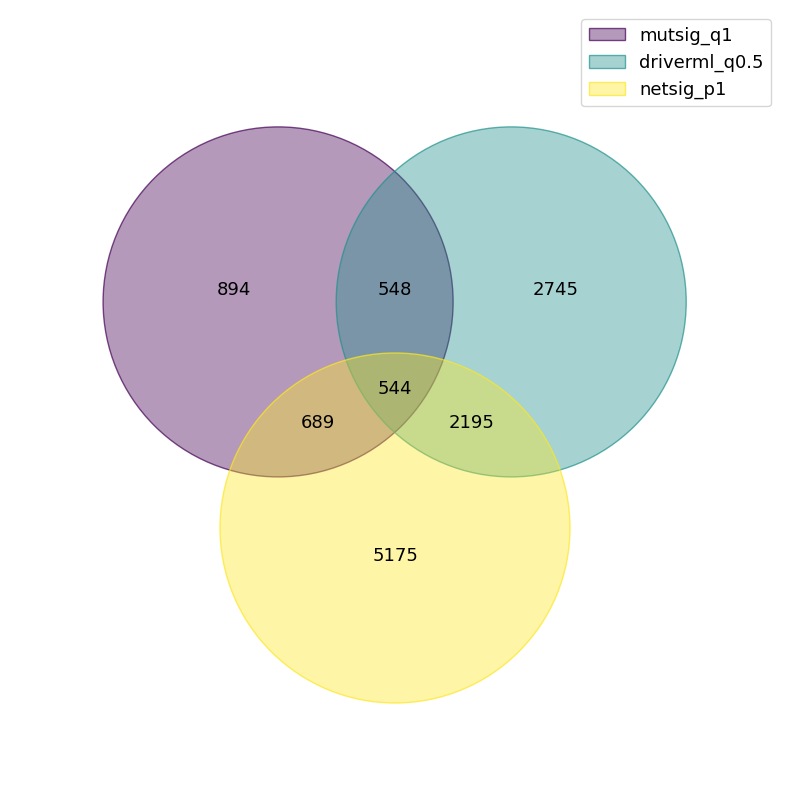

In [88]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_all.items() if any(m in k for m in {'mutsig', 'driverml', 'netsig'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_all_mutsig_driverml_netsig.png')

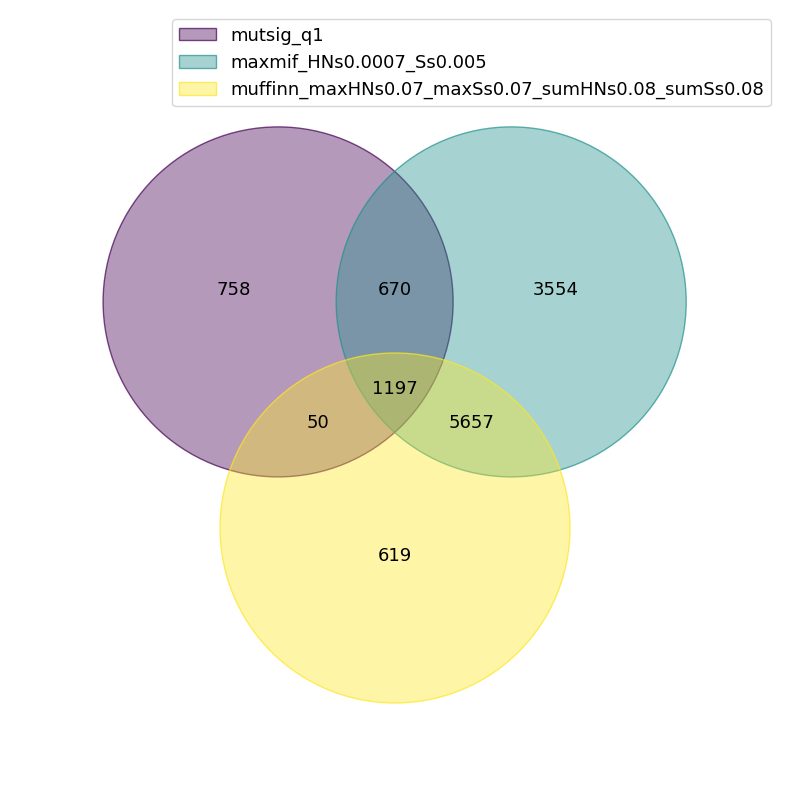

In [89]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_all.items() if any(m in k for m in {'mutsig', 'maxmif', 'muffinn'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_all_mutsig_maxmif_muffinn.png')

## venn onlyRAS (RAS exclusive)

In [90]:
genes_onlyRAS = {}

In [91]:
genes_onlyRAS[f'mutsig_q{mutsig_q_significant}'] = set(mutsig_q_sGenes_onlyRAS)
genes_onlyRAS[f'driverml_q{driverml_q_significant}'] = set(driverml_q_sGenes_onlyRAS)
genes_onlyRAS[f'mutpanning_q{mutpanning_q_significant}'] = set(mutpanning_q_sGenes_onlyRAS)
genes_onlyRAS[f'netsig_p{netsig_p_significant}'] = set(netsig_p_sGenes_onlyRAS)
genes_onlyRAS[f'maxmif_HNs{maxmifHN_s_significant}_Ss{maxmifS_s_significant}'] = set.union(set(maxmifHN_sGenes_onlyRAS), set(maxmifS_sGenes_onlyRAS))
genes_onlyRAS[f'muffinn_maxHNs{muffinnMaxHN_s_significant}_maxSs{muffinnMaxS_s_significant}_sumHNs{muffinnSumHN_s_significant}_sumSs{muffinnSumS_s_significant}'] = set.union(set(muffinnMaxHN_sGenes_onlyRAS), set(muffinnMaxS_sGenes_onlyRAS), set(muffinnSumHN_sGenes_onlyRAS), set(muffinnSumS_sGenes_onlyRAS))
genes_onlyRAS[f'hotnet2'] = set(hotnet2_sGenes_onlyRAS)

In [92]:
matrix_onlyRAS = pd.DataFrame(index=genes_onlyRAS.keys(), columns=genes_onlyRAS.keys())
for i in genes_onlyRAS.keys():
    for j in genes_onlyRAS.keys():
        intersection = len(genes_onlyRAS[i].intersection(genes_onlyRAS[j]))
        matrix_onlyRAS.loc[i, j] = f"{intersection} ({intersection/len(genes_onlyRAS[i])*100:.0f}%, {intersection/len(genes_onlyRAS[j])*100:.0f}%)"
matrix_onlyRAS

,mutsig_q1,driverml_q0.5,mutpanning_q1,netsig_p1,maxmif_HNs0.0007_Ss0.005,muffinn_maxHNs0.07_maxSs0.07_sumHNs0.08_sumSs0.08,hotnet2
mutsig_q1,"307 (100%, 100%)","54 (18%, 3%)","18 (6%, 1%)","7 (2%, 1%)","33 (11%, 4%)","58 (19%, 4%)","7 (2%, 1%)"
driverml_q0.5,"54 (3%, 18%)","1798 (100%, 100%)","270 (15%, 8%)","38 (2%, 8%)","158 (9%, 17%)","235 (13%, 17%)","74 (4%, 9%)"
mutpanning_q1,"18 (1%, 6%)","270 (8%, 15%)","3421 (100%, 100%)","76 (2%, 16%)","158 (5%, 17%)","193 (6%, 14%)","160 (5%, 18%)"
netsig_p1,"7 (1%, 2%)","38 (8%, 2%)","76 (16%, 2%)","476 (100%, 100%)","30 (6%, 3%)","39 (8%, 3%)","35 (7%, 4%)"
maxmif_HNs0.0007_Ss0.005,"33 (4%, 11%)","158 (17%, 9%)","158 (17%, 5%)","30 (3%, 6%)","907 (100%, 100%)","283 (31%, 20%)","45 (5%, 5%)"
muffinn_maxHNs0.07_maxSs0.07_sumHNs0.08_sumSs0.08,"58 (4%, 19%)","235 (17%, 13%)","193 (14%, 6%)","39 (3%, 8%)","283 (20%, 31%)","1396 (100%, 100%)","84 (6%, 10%)"
hotnet2,"7 (1%, 2%)","74 (9%, 4%)","160 (18%, 5%)","35 (4%, 7%)","45 (5%, 5%)","84 (10%, 6%)","865 (100%, 100%)"


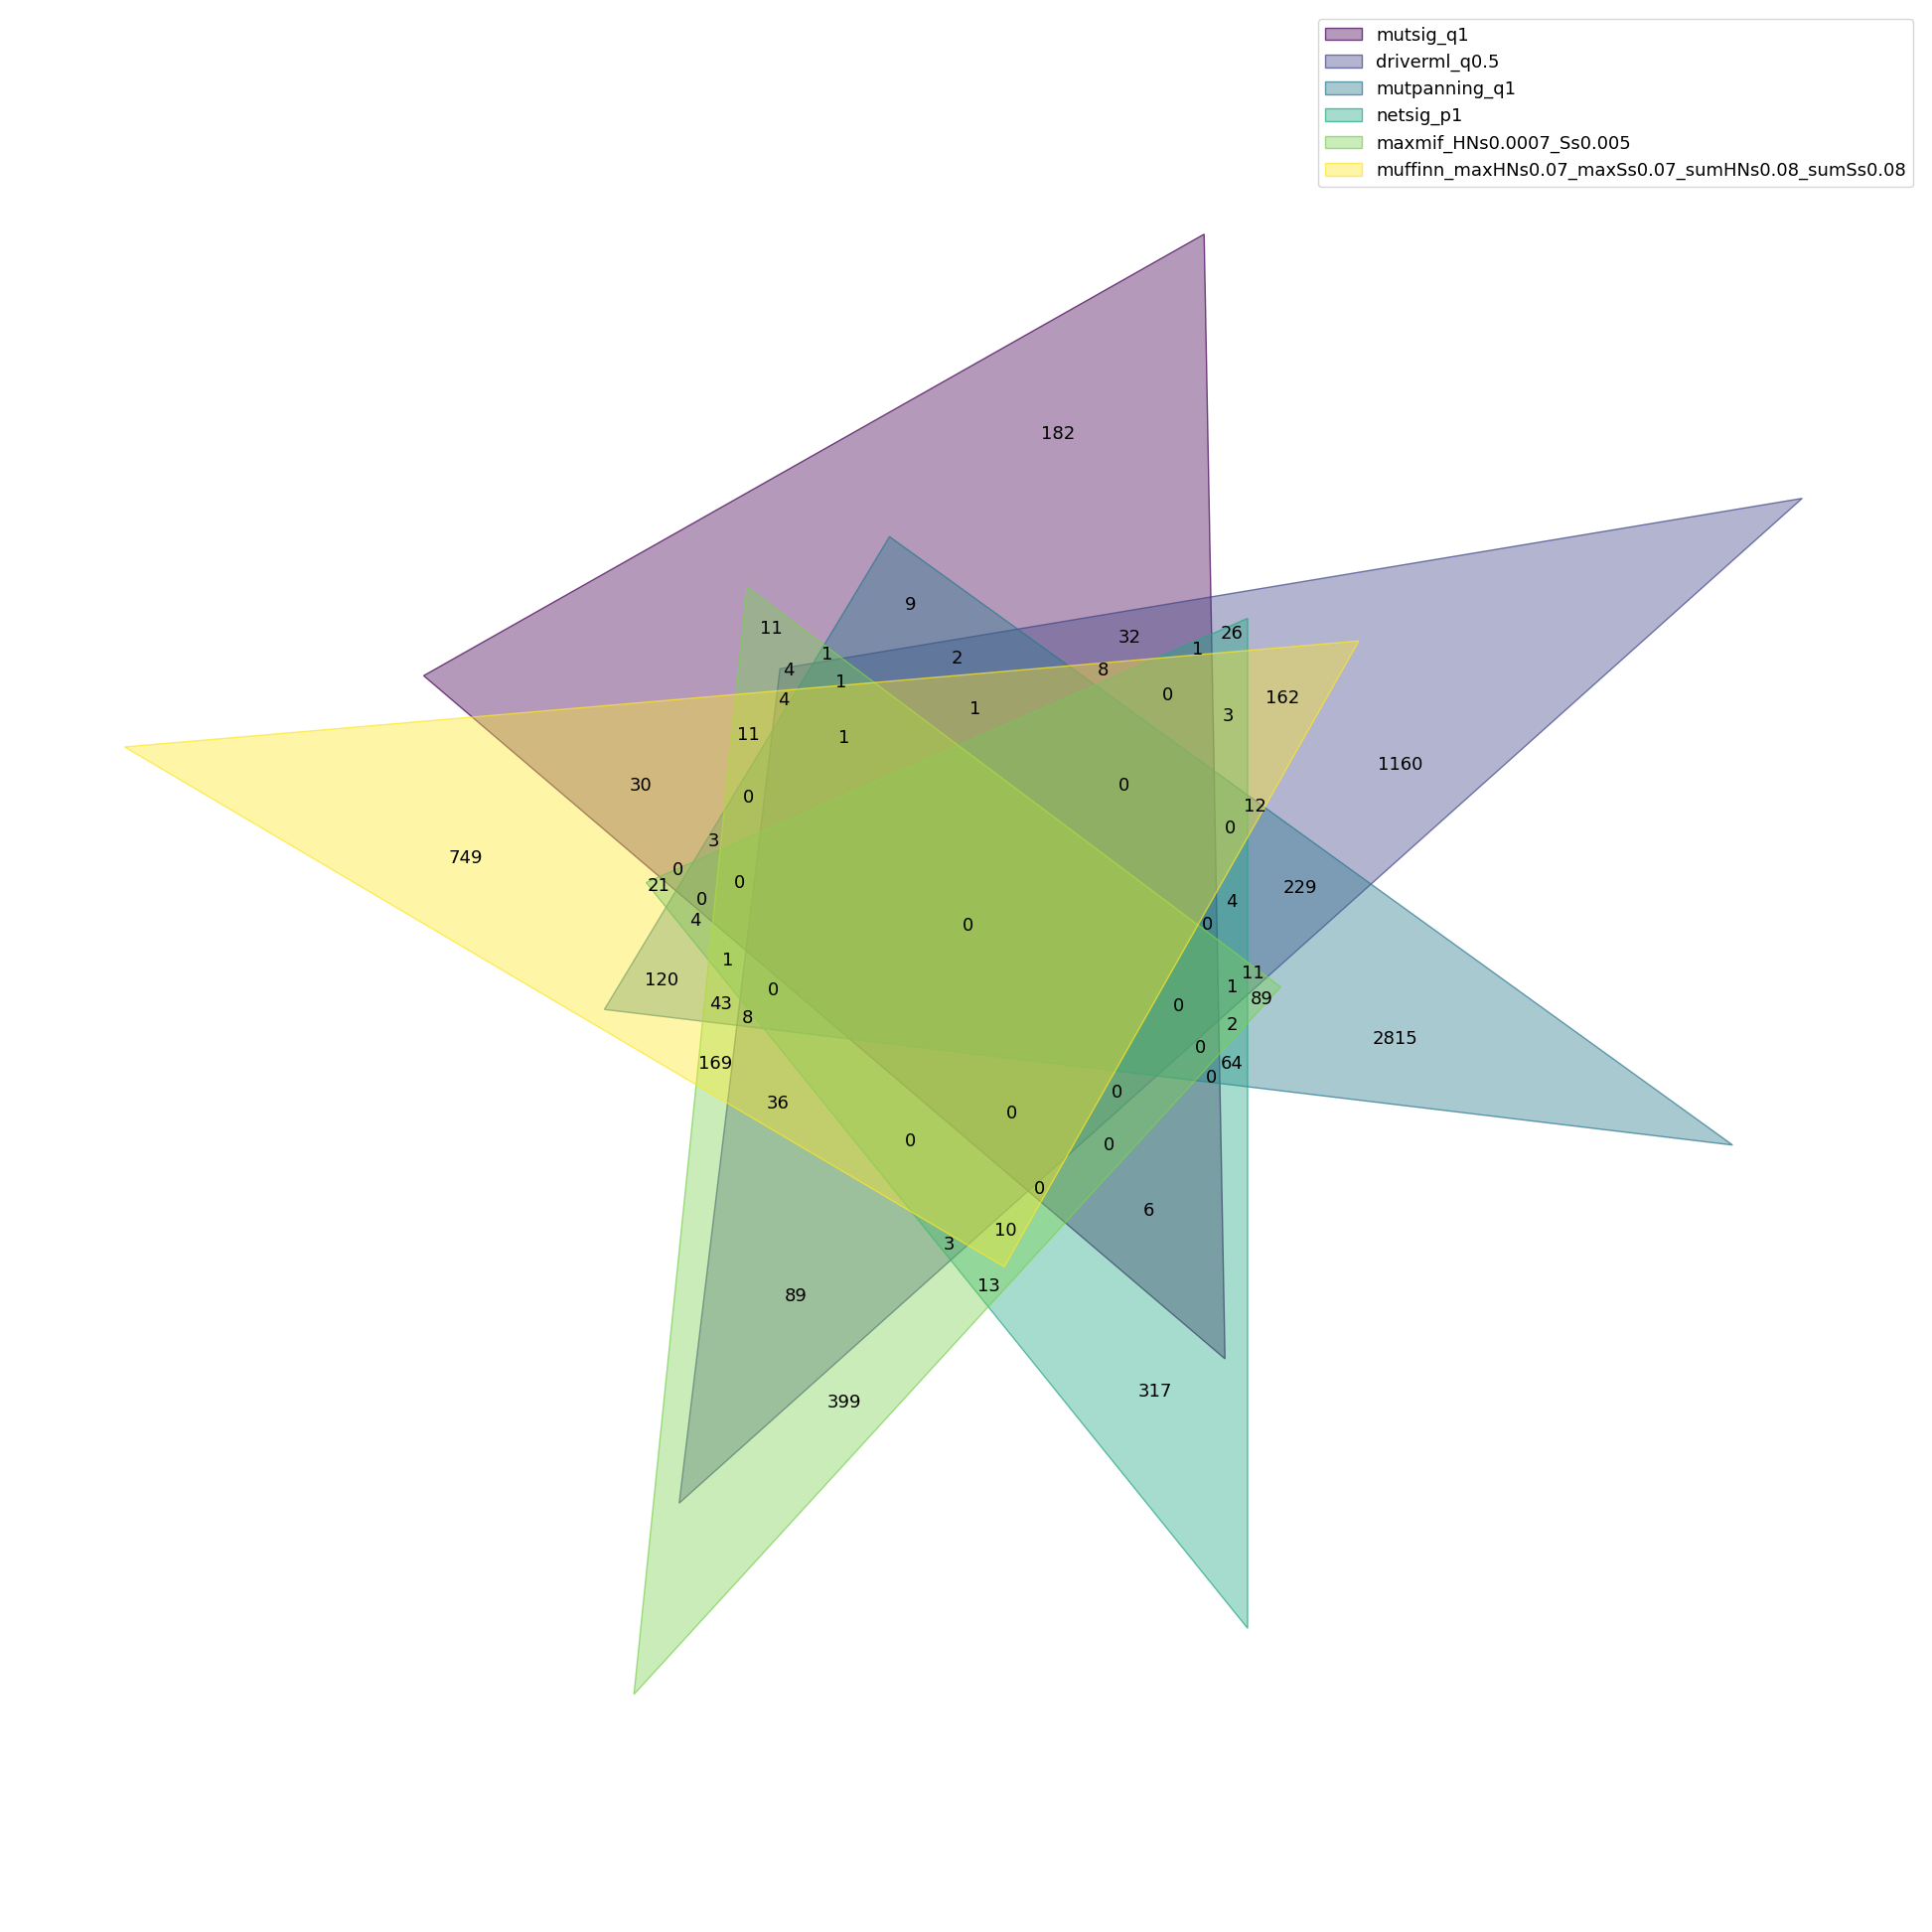

In [93]:
fig, ax = plt.subplots(figsize=(25, 25))
venn({k: v for k, v in genes_onlyRAS.items() if any(m in k for m in {'mutsig', 'driverml', 'mutpanning', 'netsig', 'maxmif', 'muffinn'})}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_onlyRAS.png')

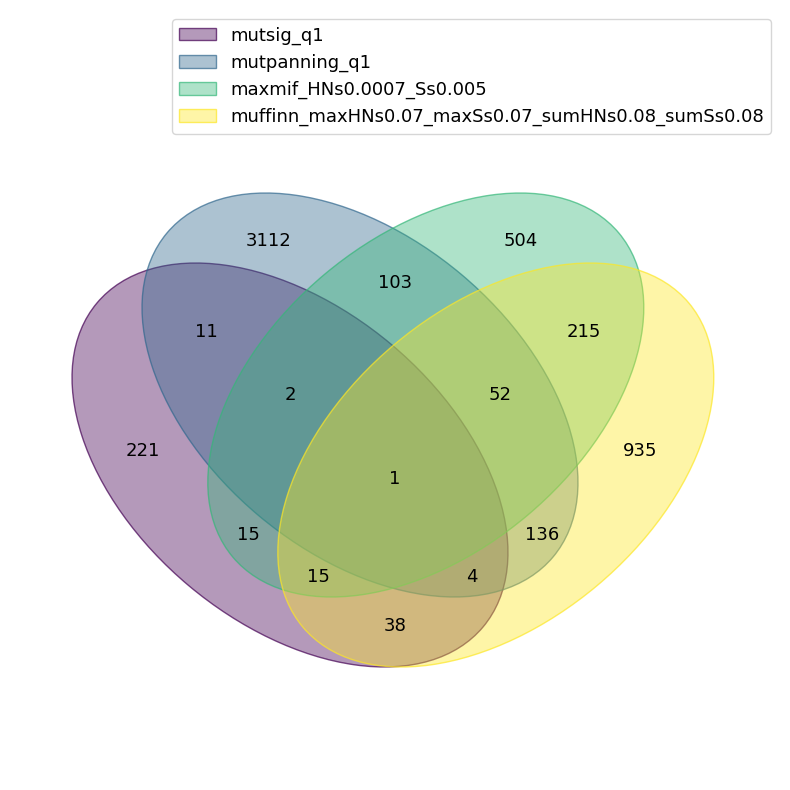

In [94]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_onlyRAS.items() if any(m in k for m in {'mutsig', 'mutpanning', 'maxmif', 'muffinn'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_onlyRAS_mutsig_mutpanning_maxmif_muffinn.png')

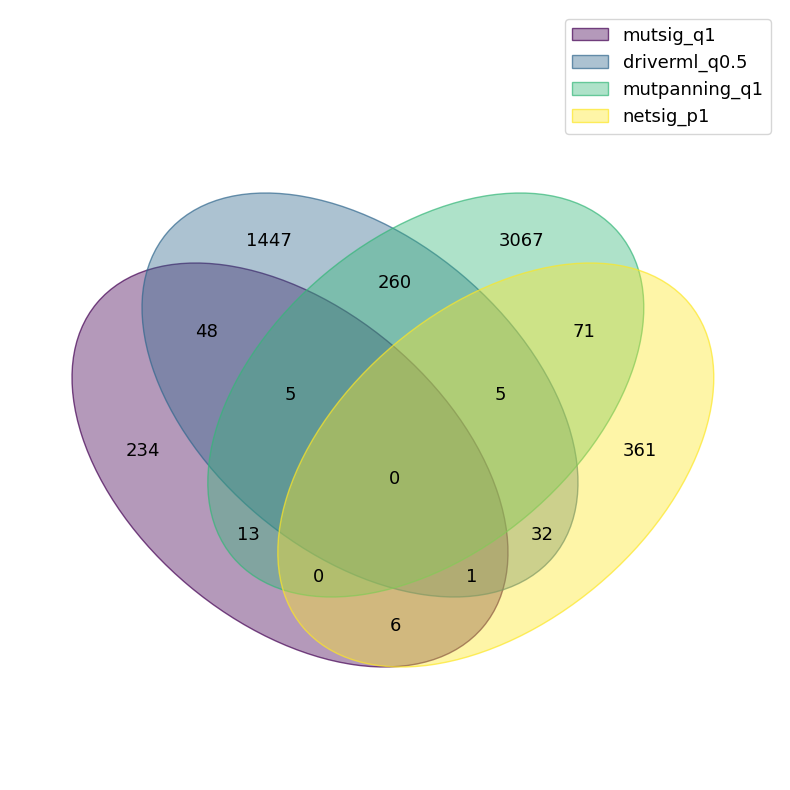

In [95]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_onlyRAS.items() if any(m in k for m in {'mutsig', 'driverml', 'mutpanning', 'netsig'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_onlyRAS_mutsig_driverml_mutpanning_netsig.png')

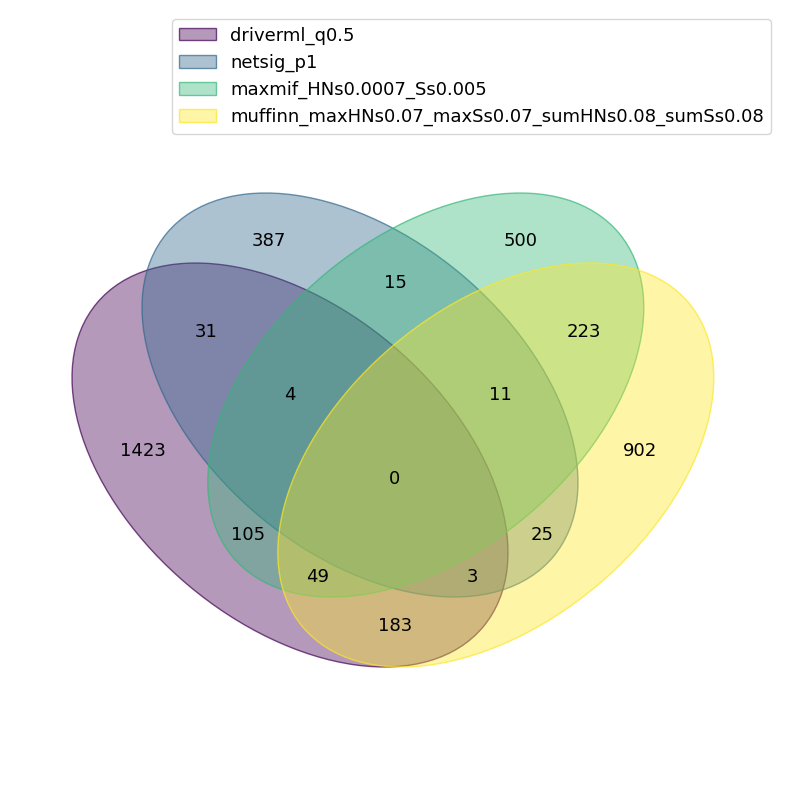

In [96]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_onlyRAS.items() if any(m in k for m in {'driverml', 'netsig', 'maxmif', 'muffinn'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_onlyRAS_driverml_netsig_maxmif_muffinn.png')

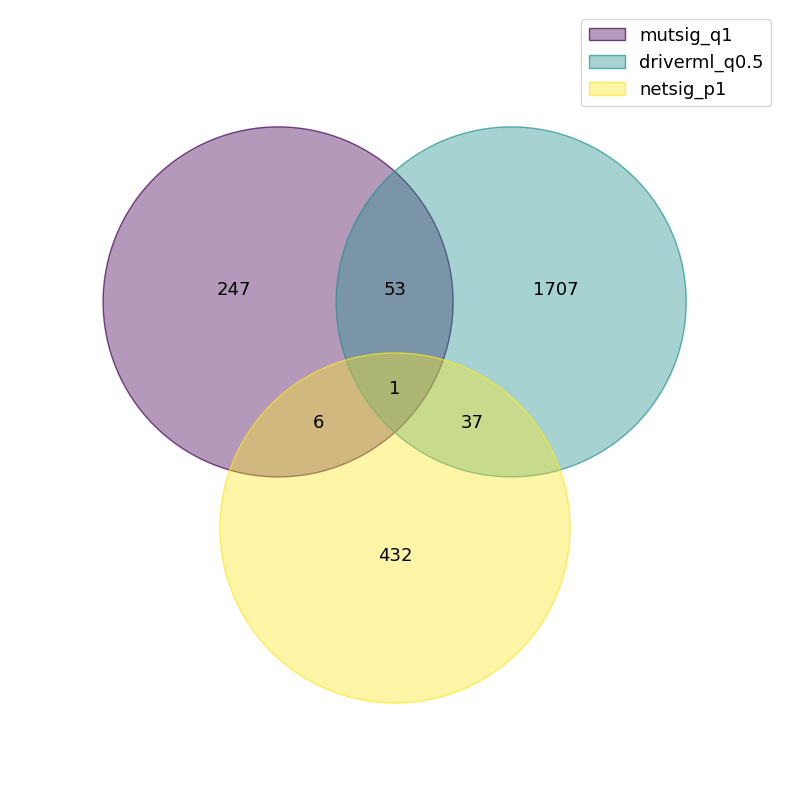

In [97]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_onlyRAS.items() if any(m in k for m in {'mutsig', 'driverml', 'netsig'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_onlyRAS_mutsig_driverml_netsig.png')

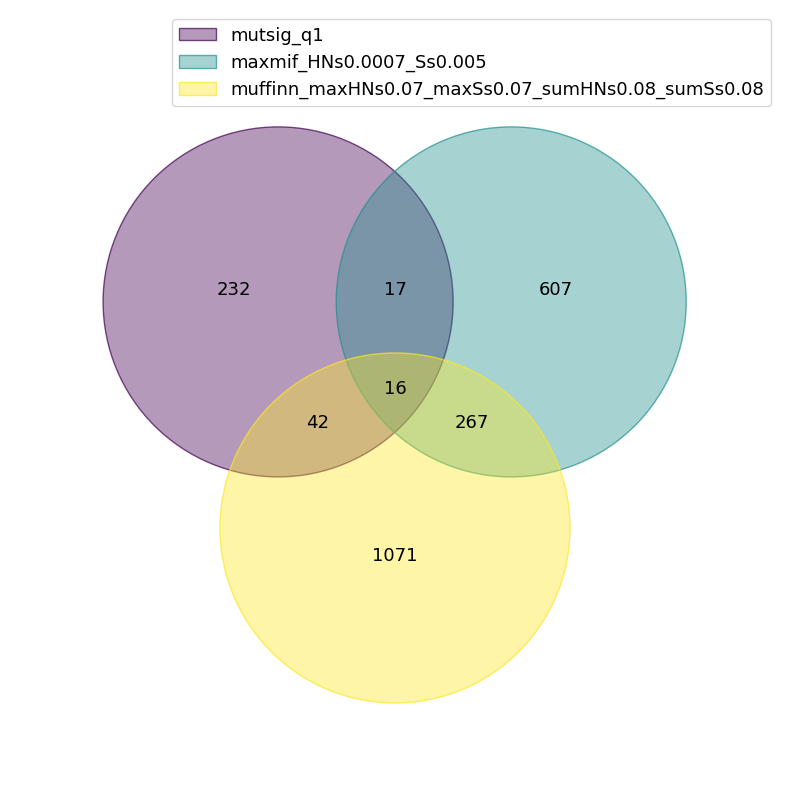

In [98]:
fig, ax = plt.subplots(figsize=(10, 10))
venn({k: v for k, v in genes_onlyRAS.items() if any(m in k for m in {'mutsig', 'maxmif', 'muffinn'} )}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_onlyRAS_mutsig_maxmif_muffinn.png')

## venn onlyRAS_onlyNonRAS (RAS exclusive and nonRAS exclusive)

In [99]:
genes_onlyRAS_onlyNonRAS = {}

In [100]:
genes_onlyRAS_onlyNonRAS[f'mutsig_q{mutsig_q_significant}'] = set(mutsig_q_sGenes_onlyRAS_onlyNonRAS)
genes_onlyRAS_onlyNonRAS[f'driverml_q{driverml_q_significant}'] = set(driverml_q_sGenes_onlyRAS_onlyNonRAS)
genes_onlyRAS_onlyNonRAS[f'mutpanning_q{mutpanning_q_significant}'] = set(mutpanning_q_sGenes_onlyRAS_onlyNonRAS)
genes_onlyRAS_onlyNonRAS[f'netsig_p{netsig_p_significant}'] = set(netsig_p_sGenes_onlyRAS_onlyNonRAS)
genes_onlyRAS_onlyNonRAS[f'maxmif_HNs{maxmifHN_s_significant}_Ss{maxmifS_s_significant}'] = set.union(set(maxmifHN_sGenes_onlyRAS_onlyNonRAS), set(maxmifS_sGenes_onlyRAS_onlyNonRAS))
genes_onlyRAS_onlyNonRAS[f'muffinn_maxHNs{muffinnMaxHN_s_significant}_maxSs{muffinnMaxS_s_significant}_sumHNs{muffinnSumHN_s_significant}_sumSs{muffinnSumS_s_significant}'] = set.union(set(muffinnMaxHN_sGenes_onlyRAS_onlyNonRAS), set(muffinnMaxS_sGenes_onlyRAS_onlyNonRAS), set(muffinnSumHN_sGenes_onlyRAS_onlyNonRAS), set(muffinnSumS_sGenes_onlyRAS_onlyNonRAS))
genes_onlyRAS_onlyNonRAS[f'hotnet2'] = hotnet2_sGenes_onlyRAS_onlyNonRAS

In [101]:
matrix_onlyRAS_onlyNonRAS = pd.DataFrame(index=genes_onlyRAS_onlyNonRAS.keys(), columns=genes_onlyRAS_onlyNonRAS.keys())
for i in genes_onlyRAS_onlyNonRAS.keys():
    for j in genes_onlyRAS_onlyNonRAS.keys():
        intersection = len(genes_onlyRAS_onlyNonRAS[i].intersection(genes_onlyRAS_onlyNonRAS[j]))
        matrix_onlyRAS_onlyNonRAS.loc[i, j] = f"{intersection} ({intersection/len(genes_onlyRAS_onlyNonRAS[i])*100:.0f}%, {intersection/len(genes_onlyRAS_onlyNonRAS[j])*100:.0f}%)"
matrix_onlyRAS_onlyNonRAS

,mutsig_q1,driverml_q0.5,mutpanning_q1,netsig_p1,maxmif_HNs0.0007_Ss0.005,muffinn_maxHNs0.07_maxSs0.07_sumHNs0.08_sumSs0.08,hotnet2
mutsig_q1,"2116 (100%, 100%)","744 (35%, 15%)","820 (39%, 10%)","329 (16%, 10%)","538 (25%, 14%)","577 (27%, 15%)","113 (5%, 11%)"
driverml_q0.5,"744 (15%, 35%)","5077 (100%, 100%)","2182 (43%, 27%)","803 (16%, 25%)","1422 (28%, 36%)","1394 (27%, 36%)","296 (6%, 28%)"
mutpanning_q1,"820 (10%, 39%)","2182 (27%, 43%)","8205 (100%, 100%)","1209 (15%, 38%)","1760 (21%, 44%)","1607 (20%, 42%)","462 (6%, 44%)"
netsig_p1,"329 (10%, 16%)","803 (25%, 16%)","1209 (38%, 15%)","3151 (100%, 100%)","752 (24%, 19%)","703 (22%, 18%)","301 (10%, 29%)"
maxmif_HNs0.0007_Ss0.005,"538 (14%, 25%)","1422 (36%, 28%)","1760 (44%, 21%)","752 (19%, 24%)","3980 (100%, 100%)","1751 (44%, 46%)","264 (7%, 25%)"
muffinn_maxHNs0.07_maxSs0.07_sumHNs0.08_sumSs0.08,"577 (15%, 27%)","1394 (36%, 27%)","1607 (42%, 20%)","703 (18%, 22%)","1751 (46%, 44%)","3832 (100%, 100%)","269 (7%, 26%)"
hotnet2,"113 (11%, 5%)","296 (28%, 6%)","462 (44%, 6%)","301 (29%, 10%)","264 (25%, 7%)","269 (26%, 7%)","1046 (100%, 100%)"


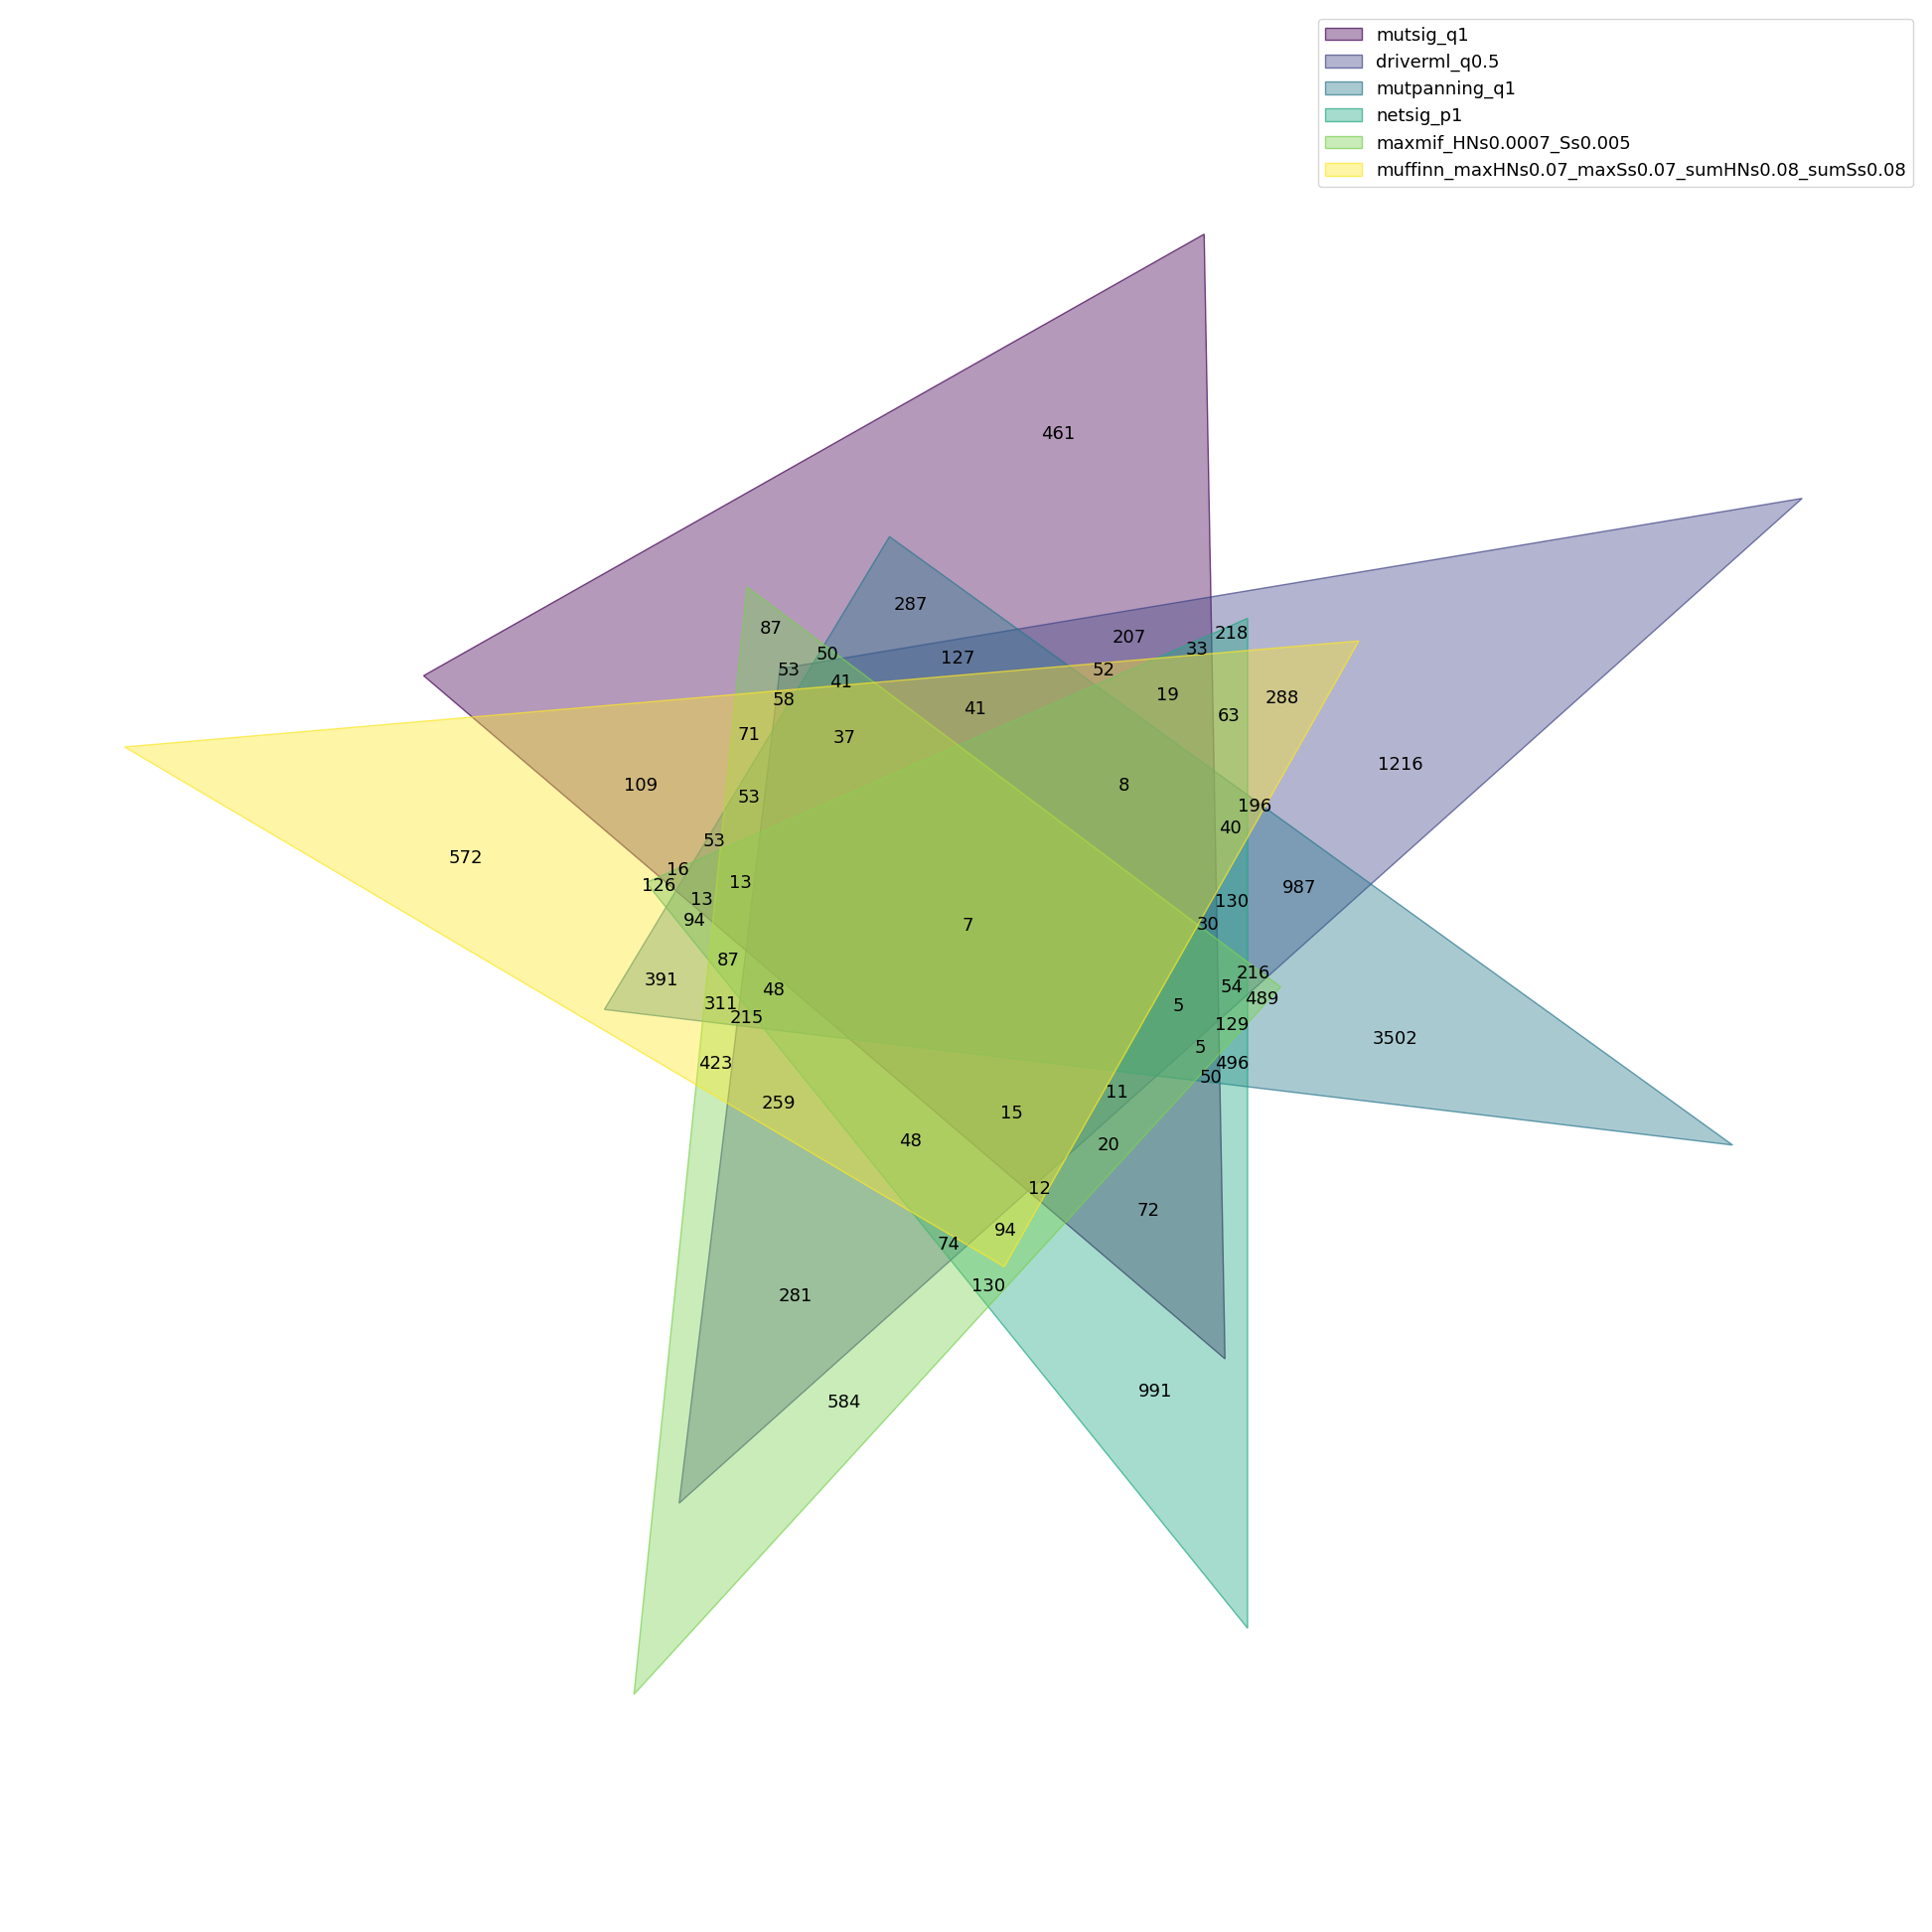

In [102]:
fig, ax = plt.subplots(figsize=(25, 25))
venn({k: v for k, v in genes_onlyRAS_onlyNonRAS.items() if any(m in k for m in {'mutsig', 'driverml', 'mutpanning', 'netsig', 'maxmif', 'muffinn'})}, ax=ax)
plt.savefig(data['plots___venn'] + 'venn_onlyRAS_onlyNonRAS.png')

## Graphs

In [103]:
genes_all = {}
genes_all[f'mutsig_q<{mutsig_q_significant}'] = set(mutsig_q_sGenes_all)
genes_all[f'driverml_q<{driverml_q_significant}'] = set(driverml_q_sGenes_all)
genes_all[f'mutpanning_q<{mutpanning_q_significant}'] = set(mutpanning_q_sGenes_all)
genes_all[f'netsig_p<{netsig_p_significant}'] = set(netsig_p_sGenes_all)
genes_all[f'maxmif_HN_s>{maxmifHN_s_significant}'] = set(maxmifHN_sGenes_all)
genes_all[f'maxmif_S_s>{maxmifS_s_significant}'] = set(maxmifS_sGenes_all)
genes_all[f'muffinn_maxHN_s>{muffinnMaxHN_s_significant}'] = set(muffinnMaxHN_sGenes_all)
genes_all[f'muffinn_maxS_s>{muffinnMaxS_s_significant}'] = set(muffinnMaxS_sGenes_all)
genes_all[f'muffinn_sumHN_s>{muffinnSumHN_s_significant}'] = set(muffinnSumHN_sGenes_all)
genes_all[f'muffinn_sumS_s>{muffinnSumS_s_significant}'] = set(muffinnSumS_sGenes_all)
genes_all[f'hotnet2_consensus'] = set(hotnet2_sGenes_all)

In [104]:
genes_RAS = {}
genes_RAS[f'mutsig_q<{mutsig_q_significant}'] = set(mutsig_q_sGenes_RAS)
genes_RAS[f'driverml_q<{driverml_q_significant}'] = set(driverml_q_sGenes_RAS)
genes_RAS[f'mutpanning_q<{mutpanning_q_significant}'] = set(mutpanning_q_sGenes_RAS)
genes_RAS[f'netsig_p<{netsig_p_significant}'] = set(netsig_p_sGenes_RAS)
genes_RAS[f'maxmif_HN_s>{maxmifHN_s_significant}'] = set(maxmifHN_sGenes_RAS)
genes_RAS[f'maxmif_S_s>{maxmifS_s_significant}'] = set(maxmifS_sGenes_RAS)
genes_RAS[f'muffinn_maxHN_s>{muffinnMaxHN_s_significant}'] = set(muffinnMaxHN_sGenes_RAS)
genes_RAS[f'muffinn_maxS_s>{muffinnMaxS_s_significant}'] = set(muffinnMaxS_sGenes_RAS)
genes_RAS[f'muffinn_sumHN_s>{muffinnSumHN_s_significant}'] = set(muffinnSumHN_sGenes_RAS)
genes_RAS[f'muffinn_sumS_s>{muffinnSumS_s_significant}'] = set(muffinnSumS_sGenes_RAS)
genes_RAS[f'hotnet2_consensus'] = set(hotnet2_sGenes_RAS)

In [105]:
genes_nonRAS = {}
genes_nonRAS[f'mutsig_q<{mutsig_q_significant}'] = set(mutsig_q_sGenes_nonRAS)
genes_nonRAS[f'driverml_q<{driverml_q_significant}'] = set(driverml_q_sGenes_nonRAS)
genes_nonRAS[f'mutpanning_q<{mutpanning_q_significant}'] = set(mutpanning_q_sGenes_nonRAS)
genes_nonRAS[f'netsig_p<{netsig_p_significant}'] = set(netsig_p_sGenes_nonRAS)
genes_nonRAS[f'maxmif_HN_s>{maxmifHN_s_significant}'] = set(maxmifHN_sGenes_nonRAS)
genes_nonRAS[f'maxmif_S_s>{maxmifS_s_significant}'] = set(maxmifS_sGenes_nonRAS)
genes_nonRAS[f'muffinn_maxHN_s>{muffinnMaxHN_s_significant}'] = set(muffinnMaxHN_sGenes_nonRAS)
genes_nonRAS[f'muffinn_maxS_s>{muffinnMaxS_s_significant}'] = set(muffinnMaxS_sGenes_nonRAS)
genes_nonRAS[f'muffinn_sumHN_s>{muffinnSumHN_s_significant}'] = set(muffinnSumHN_sGenes_nonRAS)
genes_nonRAS[f'muffinn_sumS_s>{muffinnSumS_s_significant}'] = set(muffinnSumS_sGenes_nonRAS)
genes_nonRAS[f'hotnet2_consensus'] = set(hotnet2_sGenes_nonRAS)

In [106]:
# def getStyled(genes):
#     matrix = pd.DataFrame(index=genes.keys(), columns=genes.keys())
#     for i in genes.keys():
#         for j in genes.keys():
#             intersection = len(genes[i].intersection(genes[j]))
#             matrix.at[i, j] = intersection/len(genes[i])*100

#     matrix = matrix.apply(pd.to_numeric, errors='coerce')
#     numeric_cols = matrix.select_dtypes(include='number').columns

#     # Apply the gradient to the numeric DataFrame
#     styled = matrix.style.set_table_styles(
#             [
#                 {'selector': 'thead th', 'props': [('font-weight', 'bold')]},
#                 {'selector': 'tbody th', 'props': [('font-weight', 'bold')]},
#                 {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', 'transparent')]}
#             ]
#         ) \
#         .background_gradient(cmap='YlGnBu') \
#         .format("{:.0f}%")

#     return styled

def getStyled(genes):
    # Create the initial DataFrame
    matrix = pd.DataFrame(index=genes.keys(), columns=genes.keys())
    
    for i in genes.keys():
        for j in genes.keys():
            intersection = len(genes[i].intersection(genes[j]))
            matrix.at[i, j] = intersection / len(genes[i]) * 100

    # Insert the first column with the number of genes for each method
    num_genes_col = pd.Series({key: len(value) for key, value in genes.items()})
    matrix.insert(0, 'Num Genes', num_genes_col)

    # Convert the numeric columns to apply styling
    matrix = matrix.apply(pd.to_numeric, errors='coerce')

    # Apply the gradient only to the numeric columns except 'Num Genes'
    styled = matrix.style.set_table_styles(
        [
            {'selector': 'thead th', 'props': [('font-weight', 'bold')]},
            {'selector': 'tbody th', 'props': [('font-weight', 'bold')]},
            {'selector': 'tbody tr:nth-child(even)', 'props': [('background-color', 'transparent')]}
        ]
    ).background_gradient(cmap='YlGnBu', subset=matrix.columns.difference(['Num Genes'])) \
     .format("{:.0f}%", subset=matrix.columns.difference(['Num Genes']))  # Apply format only to percentage columns
    
    return styled

In [107]:
from IPython.display import display
display(getStyled(genes_all))
display(getStyled(genes_RAS))
display(getStyled(genes_nonRAS))

,Num Genes,mutsig_q<1,driverml_q<0.5,mutpanning_q<1,netsig_p<1,maxmif_HN_s>0.0007,maxmif_S_s>0.005,muffinn_maxHN_s>0.07,muffinn_maxS_s>0.07,muffinn_sumHN_s>0.08,muffinn_sumS_s>0.08,hotnet2_consensus
mutsig_q<1,2675,100%,41%,26%,46%,57%,55%,31%,25%,26%,25%,3%
driverml_q<0.5,6032,18%,100%,39%,45%,62%,64%,37%,28%,32%,33%,5%
mutpanning_q<1,9333,8%,25%,100%,41%,40%,40%,19%,20%,15%,15%,5%
netsig_p<1,8603,14%,32%,45%,100%,63%,58%,37%,33%,28%,26%,6%
maxmif_HN_s>0.0007,8740,17%,43%,43%,62%,100%,73%,48%,34%,37%,34%,6%
maxmif_S_s>0.005,8682,17%,45%,43%,58%,73%,100%,42%,41%,34%,37%,6%
muffinn_maxHN_s>0.07,4498,18%,50%,40%,71%,94%,80%,100%,48%,62%,55%,7%
muffinn_maxS_s>0.07,4161,16%,40%,45%,69%,72%,87%,51%,100%,41%,51%,8%
muffinn_sumHN_s>0.08,3539,20%,55%,38%,68%,91%,83%,79%,48%,100%,64%,6%
muffinn_sumS_s>0.08,3551,19%,57%,38%,64%,84%,90%,70%,59%,64%,100%,6%


,Num Genes,mutsig_q<1,driverml_q<0.5,mutpanning_q<1,netsig_p<1,maxmif_HN_s>0.0007,maxmif_S_s>0.005,muffinn_maxHN_s>0.07,muffinn_maxS_s>0.07,muffinn_sumHN_s>0.08,muffinn_sumS_s>0.08,hotnet2_consensus
mutsig_q<1,526,100%,33%,16%,38%,35%,35%,39%,32%,39%,40%,3%
driverml_q<0.5,3214,5%,100%,26%,32%,35%,35%,38%,31%,40%,42%,6%
mutpanning_q<1,7324,1%,12%,100%,27%,12%,14%,15%,19%,13%,12%,5%
netsig_p<1,5577,4%,19%,35%,100%,32%,31%,37%,38%,31%,29%,7%
maxmif_HN_s>0.0007,3204,6%,35%,28%,57%,100%,56%,80%,49%,64%,56%,9%
maxmif_S_s>0.005,3330,5%,34%,30%,52%,54%,100%,56%,67%,53%,59%,9%
muffinn_maxHN_s>0.07,3717,6%,33%,29%,56%,69%,50%,100%,49%,67%,58%,8%
muffinn_maxS_s>0.07,4102,4%,24%,34%,51%,38%,54%,45%,100%,39%,49%,9%
muffinn_sumHN_s>0.08,3489,6%,37%,27%,50%,59%,51%,71%,46%,100%,64%,8%
muffinn_sumS_s>0.08,3530,6%,38%,25%,46%,51%,55%,61%,57%,64%,100%,8%


,Num Genes,mutsig_q<1,driverml_q<0.5,mutpanning_q<1,netsig_p<1,maxmif_HN_s>0.0007,maxmif_S_s>0.005,muffinn_maxHN_s>0.07,muffinn_maxS_s>0.07,muffinn_sumHN_s>0.08,muffinn_sumS_s>0.08,hotnet2_consensus
mutsig_q<1,2028,100%,38%,21%,43%,36%,30%,37%,27%,28%,29%,2%
driverml_q<0.5,4695,17%,100%,32%,42%,43%,39%,44%,30%,35%,36%,3%
mutpanning_q<1,8687,5%,17%,100%,37%,20%,19%,21%,21%,14%,14%,2%
netsig_p<1,7776,11%,25%,41%,100%,40%,36%,42%,35%,29%,27%,3%
maxmif_HN_s>0.0007,4803,15%,42%,37%,66%,100%,59%,78%,45%,54%,49%,4%
maxmif_S_s>0.005,4397,14%,41%,37%,64%,64%,100%,63%,65%,50%,55%,4%
muffinn_maxHN_s>0.07,4993,15%,41%,36%,65%,75%,56%,100%,48%,60%,54%,4%
muffinn_maxS_s>0.07,4322,13%,33%,41%,63%,50%,67%,55%,100%,41%,51%,4%
muffinn_sumHN_s>0.08,3594,16%,46%,34%,63%,72%,61%,84%,50%,100%,64%,4%
muffinn_sumS_s>0.08,3616,16%,47%,33%,59%,65%,67%,75%,61%,64%,100%,4%


In [108]:
num_genes = {'index': ['mutsig', 'driverml', 'mutpanning', 'netsig', 'maxmif HN', 'maxmif S', 'maxmif HN S', 'muffinn maxHN', 'muffinn maxS', 'muffinn sumHN', 'muffinn sumS', 'muffinn maxHN maxS sumHN sumS', 'hotnet2'],
             'threshold': [f'q<{mutsig_q_significant}', f'q<{driverml_q_significant}', f'q<{mutpanning_q_significant}', f'p<{netsig_p_significant}', f's>{maxmifHN_s_significant}', f's>{maxmifS_s_significant}', '', f's>{muffinnMaxHN_s_significant}', f's>{muffinnMaxS_s_significant}', f's>{muffinnSumHN_s_significant}', f's>{muffinnSumS_s_significant}', '', 'all'],
             'all': [len(mutsig_q_sGenes_all), len(driverml_q_sGenes_all), len(mutpanning_q_sGenes_all), len(netsig_p_sGenes_all), len(maxmifHN_sGenes_all), len(maxmifS_sGenes_all), len(maxmifHN_sGenes_all | maxmifS_sGenes_all), len(muffinnMaxHN_sGenes_all), len(muffinnMaxS_sGenes_all), len(muffinnSumHN_sGenes_all), len(muffinnSumS_sGenes_all), len(muffinnMaxHN_sGenes_all | muffinnMaxS_sGenes_all | muffinnSumHN_sGenes_all | muffinnSumS_sGenes_all), len(hotnet2_sGenes_all)],
            'RAS': [len(mutsig_q_sGenes_RAS), len(driverml_q_sGenes_RAS), len(mutpanning_q_sGenes_RAS), len(netsig_p_sGenes_RAS), len(maxmifHN_sGenes_RAS), len(maxmifS_sGenes_RAS), len(maxmifHN_sGenes_RAS | maxmifS_sGenes_RAS), len(muffinnMaxHN_sGenes_RAS), len(muffinnMaxS_sGenes_RAS), len(muffinnSumHN_sGenes_RAS), len(muffinnSumS_sGenes_RAS), len(muffinnMaxHN_sGenes_RAS | muffinnMaxS_sGenes_RAS | muffinnSumHN_sGenes_RAS | muffinnSumS_sGenes_RAS), len(hotnet2_sGenes_RAS)],
            'onlyRAS': [len(mutsig_q_sGenes_onlyRAS), len(driverml_q_sGenes_onlyRAS), len(mutpanning_q_sGenes_onlyRAS), len(netsig_p_sGenes_onlyRAS), len(maxmifHN_sGenes_onlyRAS), len(maxmifS_sGenes_onlyRAS), len(maxmifHN_sGenes_onlyRAS | maxmifS_sGenes_onlyRAS), len(muffinnMaxHN_sGenes_onlyRAS), len(muffinnMaxS_sGenes_onlyRAS), len(muffinnSumHN_sGenes_onlyRAS), len(muffinnSumS_sGenes_onlyRAS), len(muffinnMaxHN_sGenes_onlyRAS | muffinnMaxS_sGenes_onlyRAS | muffinnSumHN_sGenes_onlyRAS | muffinnSumS_sGenes_onlyRAS), len(hotnet2_sGenes_onlyRAS)],
            'onlyRAS_onlyNonRAS': [len(mutsig_q_sGenes_onlyRAS_onlyNonRAS), len(driverml_q_sGenes_onlyRAS_onlyNonRAS), len(mutpanning_q_sGenes_onlyRAS_onlyNonRAS), len(netsig_p_sGenes_onlyRAS_onlyNonRAS), len(maxmifHN_sGenes_onlyRAS_onlyNonRAS), len(maxmifS_sGenes_onlyRAS_onlyNonRAS), len(maxmifHN_sGenes_onlyRAS_onlyNonRAS | maxmifS_sGenes_onlyRAS_onlyNonRAS), len(muffinnMaxHN_sGenes_onlyRAS_onlyNonRAS), len(muffinnMaxS_sGenes_onlyRAS_onlyNonRAS), len(muffinnSumHN_sGenes_onlyRAS_onlyNonRAS), len(muffinnSumS_sGenes_onlyRAS_onlyNonRAS), len(muffinnMaxHN_sGenes_onlyRAS_onlyNonRAS | muffinnMaxS_sGenes_onlyRAS_onlyNonRAS | muffinnSumHN_sGenes_onlyRAS_onlyNonRAS | muffinnSumS_sGenes_onlyRAS_onlyNonRAS), len(hotnet2_sGenes_onlyRAS_onlyNonRAS)]}
num_genes = pd.DataFrame(num_genes, index=num_genes['index']).drop(columns='index')
num_genes

,threshold,all,RAS,onlyRAS,onlyRAS_onlyNonRAS
mutsig,q<1,2675,526,307,2116
driverml,q<0.5,6032,3214,1798,5077
mutpanning,q<1,9333,7324,3421,8205
netsig,p<1,8603,5577,476,3151
maxmif HN,s>0.0007,8740,3204,443,2485
maxmif S,s>0.005,8682,3330,548,2163
maxmif HN S,,11078,4729,907,3980
muffinn maxHN,s>0.07,4498,3717,340,1956
muffinn maxS,s>0.07,4161,4102,243,706
muffinn sumHN,s>0.08,3539,3489,523,1151


In [109]:
import matplotlib.pyplot as plt

def barGraphs_both_RAS_nonRAS(dict1, dict2, file):
    # Initialize lists to store counts for each category
    only_in_dict1_counts = []
    in_both_counts = []
    only_in_dict2_counts = []
    set_names = []  # List to store the names (keys) for labels

    # Iterate through both dictionaries
    for name1, set1 in dict1.items():
        set2 = dict2.get(name1, set())  # Get the corresponding set from dict2, default to empty set if not present

        only_in_dict1 = set1 - set2
        in_both = set1 & set2
        only_in_dict2 = set2 - set1

        # Append counts for each category
        only_in_dict1_counts.append(len(only_in_dict1))
        in_both_counts.append(len(in_both))
        only_in_dict2_counts.append(len(only_in_dict2))
        set_names.append(name1)  # Append the set name for labels

    # Create the bar plot
    bar_width = 0.5  # Width of each bar
    index = range(len(dict1))  # X-axis positions

    # Define the colors for each category
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green

    # Create the stacked bars for each category
    plt.bar(index, only_in_dict1_counts, bar_width, label='Only in RAS', color=colors[0])
    plt.bar(index, in_both_counts, bar_width, label='In Both', color=colors[1], bottom=only_in_dict1_counts)
    plt.bar(index, only_in_dict2_counts, bar_width, label='Only in nonRAS', color=colors[2], bottom=[i+j for i,j in zip(only_in_dict1_counts, in_both_counts)])

    # Labeling the plot
    plt.ylabel('Count of Elements')
    plt.xticks(index, set_names, rotation=90)  # Rotate labels to vertical
    plt.legend()

    # Show the plot
    plt.tight_layout()
    if file != None:
        plt.savefig(file)
    plt.show()

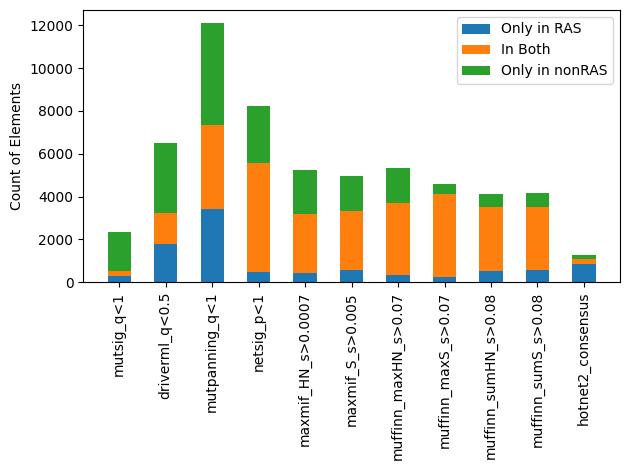

In [110]:
barGraphs_both_RAS_nonRAS(genes_RAS, genes_nonRAS, file='data/plots/both_RAS_nonRAS.png')

In [111]:
i=0
other_sets = [s for k, s in genes_RAS.items() if k != list(genes_RAS.keys())[i]]
list(genes_RAS.values())[i] & set.intersection(*other_sets)

{'ACVR2A', 'APC', 'AXIN2'}

In [112]:
import matplotlib.pyplot as plt

def barGraphs_setVsOthers(dict1, ax, displayLabels = False):
    only_in_set_counts = []
    in_some_sets_counts = []
    in_all_other_sets_counts = []
    set_names = []  # List to store the names (keys) for labels
    
    # Iterate through the dictionary
    for name1, set1 in dict1.items():
        # Set for the current iteration
        other_sets = [s for k, s in dict1.items() if k != name1]
        
        # 1. Only in the current set
        only_in_set = set1 - set().union(*other_sets)

        # 2. In other sets but not all
        in_some_sets = set1 & (set.union(*other_sets) - set.intersection(*other_sets))

        # 3. In all other sets
        in_all_other_sets = set1 & set.intersection(*other_sets)

        # Append counts for each category
        only_in_set_counts.append(len(only_in_set))
        in_some_sets_counts.append(len(in_some_sets))
        in_all_other_sets_counts.append(len(in_all_other_sets))
        set_names.append(name1)  # Append the set name for labels

    # Create the bar plot
    bar_width = 0.5  # Width of each bar
    index = range(len(dict1))  # X-axis positions

    # Define the colors for each category
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green

    # Create the stacked bars for each category
    bars_only_in_set = ax.bar(index, only_in_set_counts, bar_width, label='only by this tool', color=colors[0])
    bars_in_some_sets = ax.bar(index, in_some_sets_counts, bar_width, label='also by some other tool', color=colors[1], bottom=only_in_set_counts)
    bars_in_all_other_sets = ax.bar(index, in_all_other_sets_counts, bar_width, label='also by all other tools', color=colors[2], bottom=[i+j for i,j in zip(only_in_set_counts, in_some_sets_counts)])
    
    # Add values inside the bars
    for bars, counts in zip([bars_only_in_set, bars_in_some_sets, bars_in_all_other_sets], 
                            [only_in_set_counts, in_some_sets_counts, in_all_other_sets_counts]):
        for bar, count in zip(bars, counts):
            height = bar.get_height()
            yval = bar.get_y() + height / 2  # Position the text in the middle of the bar
            ax.text(bar.get_x() + bar.get_width() / 2, yval, str(count), ha='center', va='center', color='black', fontweight='bold')


    # Labeling the plot
    ax.set_ylabel('number of elements')
    if displayLabels:
        ax.set_xticks(index, set_names, rotation=90)  # Rotate labels to vertical
    ax.legend()

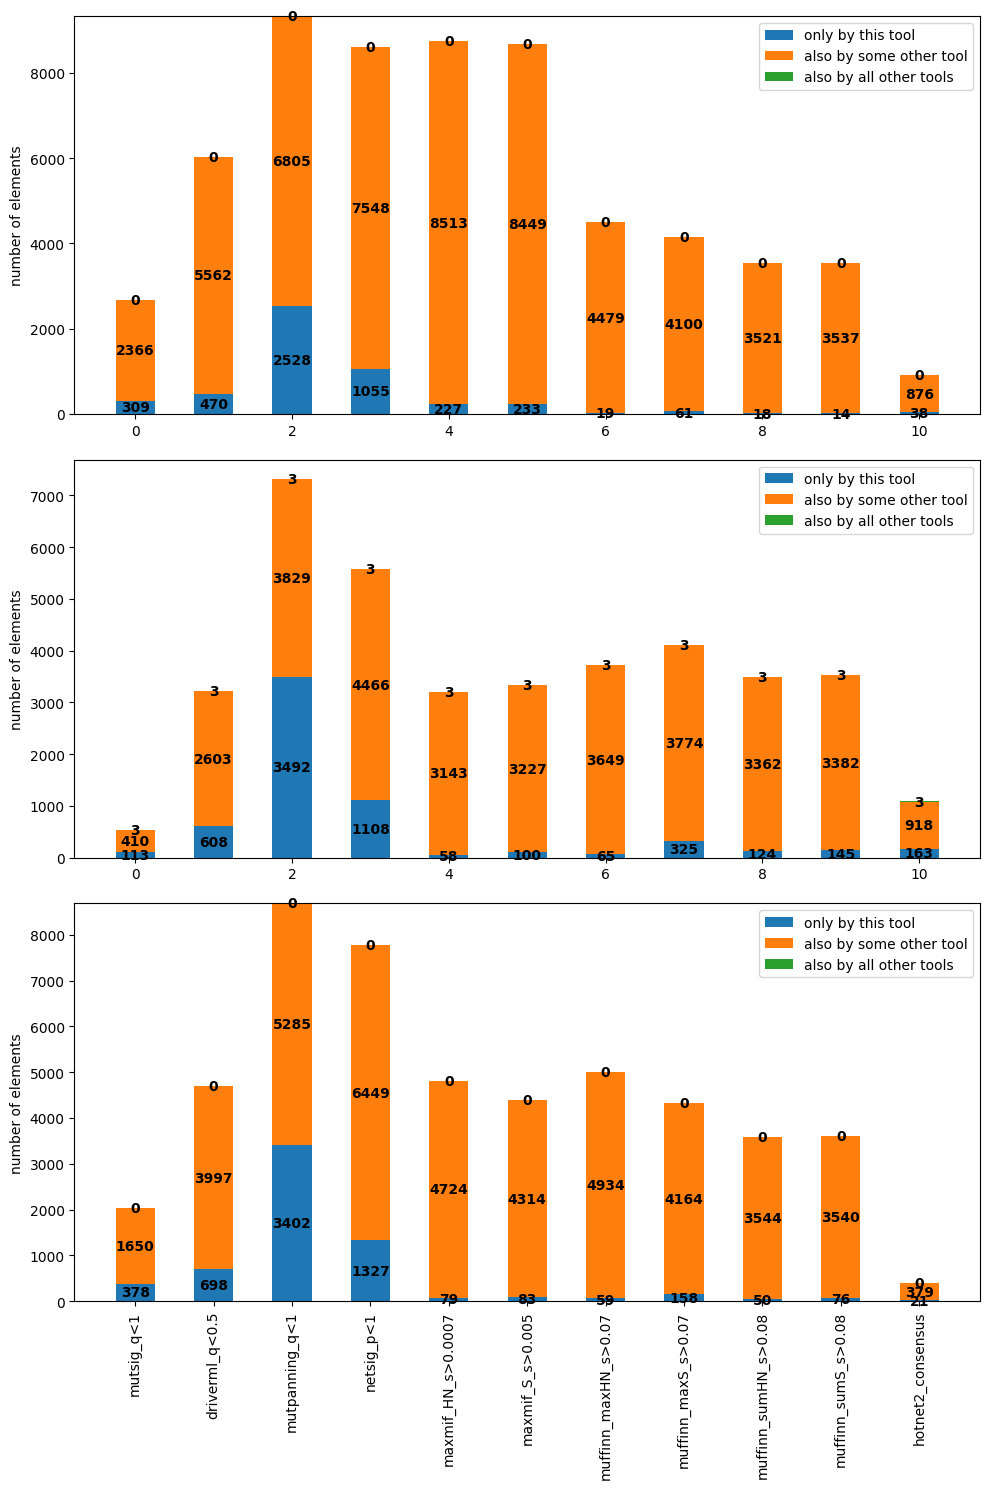

In [113]:
fig, ax = plt.subplots(3, 1, figsize=(10, 15))
barGraphs_setVsOthers(genes_all, ax.flatten()[0])
barGraphs_setVsOthers(genes_RAS, ax.flatten()[1])
barGraphs_setVsOthers(genes_nonRAS, ax.flatten()[2], displayLabels=True)

# Show the plot
plt.tight_layout()
plt.savefig('data/plots/genesByToolsComparison.png')
plt.show()

# Save sets for feature selections

In [114]:
features = {}

In [115]:
features.update( {
    'mutsig - ALL': {
        'genes': mutsig_q_sGenes_all,
        'methods': [
            {
                'method': 'mutsig',
                'measure': 'q',
                'threshold': ('<', mutsig_q_significant),
            },
        ]
    },
    'driverml - ALL': {
        'genes': driverml_q_sGenes_all,
        'methods': [
            {
                'method': 'driverml',
                'measure': 'q',
                'threshold': ('<', driverml_q_significant),
            }
        ]
    },
    'mutpanning - ALL': {
        'genes': mutpanning_q_sGenes_all,
        'methods': [
            {
                'method': 'mutpanning',
                'measure': 'q',
                'threshold': ('<', mutpanning_q_significant),
            }
        ]
    },
    'netsig - ALL': {
        'genes': netsig_p_sGenes_all,
        'methods': [
            {
                'method': 'netsig',
                'measure': 'p',
                'threshold': ('<', netsig_p_significant),
            }
        ]
    },
    'maxmif HN - ALL': {
        'genes': maxmifHN_sGenes_all,
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            }
        ]
    },
    'maxmif S - ALL': {
        'genes': maxmifS_sGenes_all,
        'methods': [
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'maxmif HN S - ALL': {
        'genes': set.union(maxmifHN_sGenes_all, maxmifS_sGenes_all),
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            },
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'muffinn maxHN - ALL': {
        'genes': muffinnMaxHN_sGenes_all,
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            }
        ]
    },
    'muffinn maxS - ALL': {
        'genes': muffinnMaxS_sGenes_all,
        'methods': [
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            }
        ]
    },
    'muffinn sumHN - ALL': {
        'genes': muffinnSumHN_sGenes_all,
        'methods': [
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            }
        ]
    },
    'muffinn sumS - ALL': {
        'genes': muffinnSumS_sGenes_all,
        'methods': [
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'muffinn maxHN maxS sumHN sumS - ALL': {
        'genes': set.union(muffinnMaxHN_sGenes_all, muffinnMaxS_sGenes_all, muffinnSumHN_sGenes_all, muffinnSumS_sGenes_all),
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            },
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            },
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            },
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'hotnet2 - ALL': {
        'genes': hotnet2_sGenes_all,
        'methods': [
            {
                'method': 'hotnet2',
                'measure': 'heat',
                'threshold': ('>=', 0)
            }
        ]
    }
})

In [116]:
features.update( {
    'mutsig - RAS': {
        'genes': mutsig_q_sGenes_RAS,
        'methods': [
            {
                'method': 'mutsig',
                'measure': 'q',
                'threshold': ('<', mutsig_q_significant),
            },
        ]
    },
    'driverml - RAS': {
        'genes': driverml_q_sGenes_RAS,
        'methods': [
            {
                'method': 'driverml',
                'measure': 'q',
                'threshold': ('<', driverml_q_significant),
            }
        ]
    },
    'mutpanning - RAS': {
        'genes': mutpanning_q_sGenes_RAS,
        'methods': [
            {
                'method': 'mutpanning',
                'measure': 'q',
                'threshold': ('<', mutpanning_q_significant),
            }
        ]
    },
    'netsig - RAS': {
        'genes': netsig_p_sGenes_RAS,
        'methods': [
            {
                'method': 'netsig',
                'measure': 'p',
                'threshold': ('<', netsig_p_significant),
            }
        ]
    },
    'maxmif HN - RAS': {
        'genes': maxmifHN_sGenes_RAS,
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            }
        ]
    },
    'maxmif S - RAS': {
        'genes': maxmifS_sGenes_RAS,
        'methods': [
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'maxmif HN S - RAS': {
        'genes': set.union(maxmifHN_sGenes_RAS, maxmifS_sGenes_RAS),
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            },
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'muffinn maxHN - RAS': {
        'genes': muffinnMaxHN_sGenes_RAS,
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            }
        ]
    },
    'muffinn maxS - RAS': {
        'genes': muffinnMaxS_sGenes_RAS,
        'methods': [
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            }
        ]
    },
    'muffinn sumHN - RAS': {
        'genes': muffinnSumHN_sGenes_RAS,
        'methods': [
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            }
        ]
    },
    'muffinn sumS - RAS': {
        'genes': muffinnSumS_sGenes_RAS,
        'methods': [
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'muffinn maxHN maxS sumHN sumS - RAS': {
        'genes': set.union(muffinnMaxHN_sGenes_RAS, muffinnMaxS_sGenes_RAS, muffinnSumHN_sGenes_RAS, muffinnSumS_sGenes_RAS),
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            },
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            },
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            },
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'hotnet2 - RAS': {
        'genes': hotnet2_sGenes_RAS,
        'methods': [
            {
                'method': 'hotnet2',
                'measure': 'heat',
                'threshold': ('>=', 0)
            }
        ]
    }
})

In [117]:
features.update( {
    
    'mutsig - onlyRAS': {
        'genes': mutsig_q_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'mutsig',
                'measure': 'q',
                'threshold': ('<', mutsig_q_significant),
            },
        ]
    },
    'driverml - onlyRAS': {
        'genes': driverml_q_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'driverml',
                'measure': 'q',
                'threshold': ('<', driverml_q_significant),
            }
        ]
    },
    'mutpanning - onlyRAS': {
        'genes': mutpanning_q_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'mutpanning',
                'measure': 'q',
                'threshold': ('<', mutpanning_q_significant),
            }
        ]
    },
    'netsig - onlyRAS': {
        'genes': netsig_p_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'netsig',
                'measure': 'p',
                'threshold': ('<', netsig_p_significant),
            }
        ]
    },
    'maxmif HN - onlyRAS': {
        'genes': maxmifHN_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            }
        ]
    },
    'maxmif S - onlyRAS': {
        'genes': maxmifS_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'maxmif HN S - onlyRAS': {
        'genes': set.union(maxmifHN_sGenes_onlyRAS, maxmifS_sGenes_onlyRAS),
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            },
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'muffinn maxHN - onlyRAS': {
        'genes': muffinnMaxHN_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            }
        ]
    },
    'muffinn maxS - onlyRAS': {
        'genes': muffinnMaxS_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            }
        ]
    },
    'muffinn sumHN - onlyRAS': {
        'genes': muffinnSumHN_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            }
        ]
    },
    'muffinn sumS - onlyRAS': {
        'genes': muffinnSumS_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'muffinn maxHN maxS sumHN sumS - onlyRAS': {
        'genes': set.union(muffinnMaxHN_sGenes_onlyRAS, muffinnMaxS_sGenes_onlyRAS, muffinnSumHN_sGenes_onlyRAS, muffinnSumS_sGenes_onlyRAS),
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            },
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            },
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            },
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'hotnet2 - onlyRAS': {
        'genes': hotnet2_sGenes_onlyRAS,
        'methods': [
            {
                'method': 'hotnet2',
                'measure': 'heat',
                'threshold': ('>=', 0)
            }
        ]
    }

})

In [118]:
features.update( {
    
    'mutsig - onlyRAS_onlyNonRAS': {
        'genes': mutsig_q_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'mutsig',
                'measure': 'q',
                'threshold': ('<', mutsig_q_significant),
            },
        ]
    },
    'driverml - onlyRAS_onlyNonRAS': {
        'genes': driverml_q_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'driverml',
                'measure': 'q',
                'threshold': ('<', driverml_q_significant),
            }
        ]
    },
    'mutpanning - onlyRAS_onlyNonRAS': {
        'genes': mutpanning_q_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'mutpanning',
                'measure': 'q',
                'threshold': ('<', mutpanning_q_significant),
            }
        ]
    },
    'netsig - onlyRAS_onlyNonRAS': {
        'genes': netsig_p_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'netsig',
                'measure': 'p',
                'threshold': ('<', netsig_p_significant),
            }
        ]
    },
    'maxmif HN - onlyRAS_onlyNonRAS': {
        'genes': maxmifHN_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            }
        ]
    },
    'maxmif S - onlyRAS_onlyNonRAS': {
        'genes': maxmifS_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'maxmif HN S - onlyRAS_onlyNonRAS': {
        'genes': set.union(maxmifHN_sGenes_onlyRAS_onlyNonRAS, maxmifS_sGenes_onlyRAS_onlyNonRAS),
        'methods': [
            {
                'method': 'maxmif HN',
                'measure': 'score',
                'threshold': ('>', maxmifHN_s_significant),
            },
            {
                'method': 'maxmif S',
                'measure': 'score',
                'threshold': ('>', maxmifS_s_significant),
            }
        ]
    },
    'muffinn maxHN - onlyRAS_onlyNonRAS': {
        'genes': muffinnMaxHN_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            }
        ]
    },
    'muffinn maxS - onlyRAS_onlyNonRAS': {
        'genes': muffinnMaxS_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            }
        ]
    },
    'muffinn sumHN - onlyRAS_onlyNonRAS': {
        'genes': muffinnSumHN_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            }
        ]
    },
    'muffinn sumS - onlyRAS_onlyNonRAS': {
        'genes': muffinnSumS_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'muffinn maxHN maxS sumHN sumS - onlyRAS_onlyNonRAS': {
        'genes': set.union(muffinnMaxHN_sGenes_onlyRAS_onlyNonRAS, muffinnMaxS_sGenes_onlyRAS_onlyNonRAS, muffinnSumHN_sGenes_onlyRAS_onlyNonRAS, muffinnSumS_sGenes_onlyRAS_onlyNonRAS),
        'methods': [
            {
                'method': 'muffinn maxHN',
                'measure': 'score',
                'threshold': ('>', muffinnMaxHN_s_significant),
            },
            {
                'method': 'muffinn maxS',
                'measure': 'score',
                'threshold': ('>', muffinnMaxS_s_significant),
            },
            {
                'method': 'muffinn sumHN',
                'measure': 'score',
                'threshold': ('>', muffinnSumHN_s_significant),
            },
            {
                'method': 'muffinn sumS',
                'measure': 'score',
                'threshold': ('>', muffinnSumS_s_significant),
            }
        ]
    },
    'hotnet2 - onlyRAS_onlyNonRAS': {
        'genes': hotnet2_sGenes_onlyRAS_onlyNonRAS,
        'methods': [
            {
                'method': 'hotnet2',
                'measure': 'heat',
                'threshold': ('>=', 0)
            }
        ]
    }

})

In [119]:
class SetEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, set):
            return list(obj)  # Convert set to list
        return super().default(obj)

# json.dump(features, open(data['ml'] + 'tools_features_selection.json', 'w'), indent=4, cls=SetEncoder)